# Nassau Candy Distributor
## Data Audit & Quality Assessment

**Project:** Product Line Profitability & Margin Performance Analysis  
**Notebook:** 01 — Data Audit  
**Dataset:** Nassau Candy Distributor

---

### Purpose

This notebook performs a systematic audit of the raw dataset before any
data cleaning, transformation, or profitability analysis is performed.

The audit evaluates:

- Dataset structure
- Schema and data types
- Data completeness
- Duplicate records
- Identifier integrity
- Numerical validity
- Financial consistency
- Date integrity
- Categorical consistency
- Product and division relationships

### Analytical Principle

**Audit → Decide → Clean → Analyze → Validate → Communicate**

No data will be modified or removed during this audit.

## 1. Business Context

Nassau Candy Distributor requires visibility into product profitability
rather than relying only on sales volume.

The analysis is intended to determine:

1. Which products generate the highest gross profit?
2. Which products have strong or weak gross margins?
3. Whether high-sales products are also profitable.
4. Which divisions perform strongly or weakly.
5. How concentrated revenue and profit are across products.
6. Which products may represent margin risk.
7. Where pricing or cost-related investigation may be required.

The technical documentation identifies product profitability, division
performance, Pareto analysis, and cost diagnostics as core analytical areas.

## 2. Audit Objectives

The purpose of this audit is to determine whether the raw dataset is
structurally and analytically reliable.

The audit will answer:

- Does the dataset contain the expected columns?
- Are the required fields complete?
- Are records duplicated?
- Are identifiers behaving as expected?
- Are numerical values valid?
- Does Gross Profit reconcile with Sales − Cost?
- Are dates valid and logically interpretable?
- Are categorical values consistent?
- Are products consistently assigned to divisions?

The output of this notebook will be a documented set of data-quality
findings and cleaning decisions for the next phase.

In [75]:
# ============================================================
# Import Required Libraries
# ============================================================

import pandas as pd
import numpy as np

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

# Display numerical values with two decimal places
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load the Raw Dataset

The raw dataset is loaded directly from the `data/raw` directory.

The raw dataset will be treated as the source of truth.

No values will be modified during the audit stage.

In [76]:
# Path to the original raw dataset
file_path = "../data/raw/Nassau Candy Distributor.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 1. Dataset Structure

Before examining individual values, we first establish the overall structure
of the dataset.

We will identify:

- Number of records (rows)
- Number of variables (columns)
- Column names
- Data types
- Approximate memory usage

This establishes the initial schema and helps identify columns that may require
type conversion or further validation.

**Important:** No data transformation will be performed at this stage.

In [77]:
# Display the basic dimensions of the dataset
print("Dataset Shape:")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

# Display the column names in their original order
print("\nColumn Names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

# Display the data type of each column
print("\nData Types:")
print(df.dtypes)

# Display memory usage of the DataFrame
print("\nMemory Usage:")
print(f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

Dataset Shape:
Rows    : 10,194
Columns : 18

Column Names:
01. Row ID
02. Order ID
03. Order Date
04. Ship Date
05. Ship Mode
06. Customer ID
07. Country/Region
08. City
09. State/Province
10. Postal Code
11. Division
12. Region
13. Product ID
14. Product Name
15. Sales
16. Units
17. Gross Profit
18. Cost

Data Types:
Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID         int64
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Division              str
Region                str
Product ID            str
Product Name          str
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

Memory Usage:
2.90 MB


## 2. Data Completeness & Missing Value Audit

The next step is to determine whether the dataset contains missing values.

Missing values can affect:

- Profitability calculations
- Product and division comparisons
- Customer analysis
- Time-based analysis
- Dashboard metrics

We will calculate both the **missing-value count** and **missing-value percentage**
for every column.

At this stage, we are only measuring data quality — no values will be filled,
removed, or modified.

In [78]:
# Count the number of missing values in each column
missing_count = df.isna().sum()

# Calculate the percentage of missing values in each column
missing_percentage = (missing_count / len(df)) * 100

# Combine both measures into a single audit table
missing_audit = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Sort columns by missing-value count in descending order
missing_audit = missing_audit.sort_values(
    by="Missing Count",
    ascending=False
)

# Display the completeness audit
print("Missing Value Audit")
print("=" * 60)
print(missing_audit)

# Overall completeness check
total_missing = missing_count.sum()

print("\nOverall Missing Values:")
print(f"Total missing cells: {total_missing:,}")

if total_missing == 0:
    print("Status: No missing values detected.")
else:
    print("Status: Missing values detected. Further investigation required.")

Missing Value Audit
                Missing Count  Missing Percentage
Row ID                      0                0.00
Order ID                    0                0.00
Order Date                  0                0.00
Ship Date                   0                0.00
Ship Mode                   0                0.00
Customer ID                 0                0.00
Country/Region              0                0.00
City                        0                0.00
State/Province              0                0.00
Postal Code                 0                0.00
Division                    0                0.00
Region                      0                0.00
Product ID                  0                0.00
Product Name                0                0.00
Sales                       0                0.00
Units                       0                0.00
Gross Profit                0                0.00
Cost                        0                0.00

Overall Missing Values:
Total

## 3. Duplicate Record Audit

Duplicate records can lead to double-counting of:

- Sales
- Gross Profit
- Cost
- Units
- Orders

However, repeated **Order IDs are not automatically duplicates** because a single
order can contain multiple product lines.

Therefore, this audit will first check for **exact duplicate rows** in the raw
dataset.

We will not remove any records at this stage.

In [79]:
# Identify rows that are exact duplicates across all columns
duplicate_mask = df.duplicated(keep=False)

# Count the number of exact duplicate rows
duplicate_count = duplicate_mask.sum()

# Calculate the percentage of duplicate rows
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate Record Audit")
print("=" * 60)
print(f"Total records            : {len(df):,}")
print(f"Exact duplicate records  : {duplicate_count:,}")
print(f"Duplicate percentage     : {duplicate_percentage:.2f}%")

# Display a sample only if duplicates are found
if duplicate_count > 0:
    print("\nSample duplicate records:")
    display(df[duplicate_mask].head(10))
else:
    print("\nStatus: No exact duplicate rows detected.")

Duplicate Record Audit
Total records            : 10,194
Exact duplicate records  : 0
Duplicate percentage     : 0.00%

Status: No exact duplicate rows detected.


## 4. Identifier Integrity Audit

Identifiers are critical for reliable analysis and data relationships.

We will examine:

- `Row ID` — expected to uniquely identify each record
- `Order ID` — may legitimately repeat because an order can contain multiple
  product-line records
- `Customer ID` — expected to repeat across multiple purchases by the same customer
- `Product ID` — expected to repeat across multiple transactions for the same product

The purpose is to understand the **granularity of the dataset** before performing
order-level or product-level analysis.

No records will be removed or modified.

In [80]:
# Calculate unique counts for the main identifier columns
identifier_summary = pd.DataFrame({
    "Total Rows": [len(df)] * 4,
    "Unique Values": [
        df["Row ID"].nunique(),
        df["Order ID"].nunique(),
        df["Customer ID"].nunique(),
        df["Product ID"].nunique()
    ]
}, index=["Row ID", "Order ID", "Customer ID", "Product ID"])

# Calculate how many times each identifier appears on average
identifier_summary["Rows per Unique ID"] = (
    identifier_summary["Total Rows"] /
    identifier_summary["Unique Values"]
)

print("Identifier Integrity Audit")
print("=" * 70)
print(identifier_summary.round(2))

# Explicit uniqueness check for Row ID
print("\nRow ID Uniqueness Check:")
if df["Row ID"].is_unique:
    print("Status: Row ID is unique for every record.")
else:
    print("Status: Duplicate Row IDs detected. Further investigation required.")

# Check repeated Order IDs
order_repeated = (df["Order ID"].value_counts() > 1).sum()

print("\nOrder ID Repetition:")
print(f"Order IDs appearing more than once: {order_repeated:,}")
print("Interpretation: Repeated Order IDs can be valid in a line-item dataset.")

Identifier Integrity Audit
             Total Rows  Unique Values  Rows per Unique ID
Row ID            10194          10194                1.00
Order ID          10194           8549                1.19
Customer ID       10194           5044                2.02
Product ID        10194             15              679.60

Row ID Uniqueness Check:
Status: Row ID is unique for every record.

Order ID Repetition:
Order IDs appearing more than once: 1,373
Interpretation: Repeated Order IDs can be valid in a line-item dataset.


## 5. Numerical Field Validity Audit

The profitability analysis depends heavily on the numerical fields:

- `Sales`
- `Cost`
- `Gross Profit`
- `Units`

Before calculating profitability metrics, we need to identify potentially
invalid numerical values.

We will check for:

- Zero values
- Negative values
- Missing values
- Basic numerical ranges

These checks help determine whether records could create misleading
profitability calculations.

No records will be modified or removed during this audit.

In [81]:
# Define the key numerical columns used in the profitability analysis
numeric_columns = ["Sales", "Cost", "Gross Profit", "Units"]

# Create an audit table for numerical validity
numeric_audit = pd.DataFrame(index=numeric_columns)

# Count zero values in each numerical column
numeric_audit["Zero Values"] = [
    (df[column] == 0).sum()
    for column in numeric_columns
]

# Count negative values in each numerical column
numeric_audit["Negative Values"] = [
    (df[column] < 0).sum()
    for column in numeric_columns
]

# Calculate minimum and maximum values
numeric_audit["Minimum"] = [
    df[column].min()
    for column in numeric_columns
]

numeric_audit["Maximum"] = [
    df[column].max()
    for column in numeric_columns
]

print("Numerical Field Validity Audit")
print("=" * 80)
print(numeric_audit)

# Overall status
if (
    numeric_audit["Zero Values"].sum() == 0
    and numeric_audit["Negative Values"].sum() == 0
):
    print("\nStatus: No zero or negative values detected.")
else:
    print("\nStatus: Potentially invalid numerical values detected.")

Numerical Field Validity Audit
              Zero Values  Negative Values  Minimum  Maximum
Sales                   0                0     1.25   260.00
Cost                    0                0     0.60   130.00
Gross Profit            0                0     0.25   130.00
Units                   0                0     1.00    14.00

Status: No zero or negative values detected.


## 5. Numerical Field Validity Audit

The profitability analysis depends heavily on the numerical fields:

- `Sales`
- `Cost`
- `Gross Profit`
- `Units`

Before calculating profitability metrics, we need to identify potentially
invalid numerical values.

We will check for:

- Zero values
- Negative values
- Missing values
- Basic numerical ranges

These checks help determine whether records could create misleading
profitability calculations.

No records will be modified or removed during this audit.

In [82]:
# Define the key numerical columns used in the profitability analysis
numeric_columns = ["Sales", "Cost", "Gross Profit", "Units"]

# Create an audit table for numerical validity
numeric_audit = pd.DataFrame(index=numeric_columns)

# Count zero values in each numerical column
numeric_audit["Zero Values"] = [
    (df[column] == 0).sum()
    for column in numeric_columns
]

# Count negative values in each numerical column
numeric_audit["Negative Values"] = [
    (df[column] < 0).sum()
    for column in numeric_columns
]

# Calculate minimum and maximum values
numeric_audit["Minimum"] = [
    df[column].min()
    for column in numeric_columns
]

numeric_audit["Maximum"] = [
    df[column].max()
    for column in numeric_columns
]

print("Numerical Field Validity Audit")
print("=" * 80)
print(numeric_audit)

# Overall status
if (
    numeric_audit["Zero Values"].sum() == 0
    and numeric_audit["Negative Values"].sum() == 0
):
    print("\nStatus: No zero or negative values detected.")
else:
    print("\nStatus: Potentially invalid numerical values detected.")

Numerical Field Validity Audit
              Zero Values  Negative Values  Minimum  Maximum
Sales                   0                0     1.25   260.00
Cost                    0                0     0.60   130.00
Gross Profit            0                0     0.25   130.00
Units                   0                0     1.00    14.00

Status: No zero or negative values detected.


## 6. Financial Reconciliation Audit

The dataset documentation defines:

**Gross Profit = Sales − Cost**

Because Gross Profit is a core measure for this project, we must verify this
relationship at the individual-record level.

The audit will calculate:

- Expected Gross Profit = Sales − Cost
- Difference between reported and expected Gross Profit
- Number of records that fail the reconciliation check
- Maximum absolute difference

A tolerance is used to account for minor floating-point precision differences.

No financial values will be modified during this audit.

In [83]:
# Calculate the expected gross profit directly from Sales and Cost
expected_gross_profit = df["Sales"] - df["Cost"]

# Calculate the difference between reported and expected gross profit
profit_difference = df["Gross Profit"] - expected_gross_profit

# Define a small tolerance for floating-point precision
tolerance = 0.01

# Identify records where the difference exceeds the tolerance
reconciliation_errors = profit_difference.abs() > tolerance

# Count reconciliation failures
error_count = reconciliation_errors.sum()

# Calculate the largest absolute difference
max_difference = profit_difference.abs().max()

print("Financial Reconciliation Audit")
print("=" * 70)
print("Formula: Gross Profit = Sales - Cost")
print(f"Tolerance                    : {tolerance:.2f}")
print(f"Records checked              : {len(df):,}")
print(f"Reconciliation errors        : {error_count:,}")
print(f"Maximum absolute difference  : {max_difference:.4f}")

# Display a sample of problematic records if any exist
if error_count > 0:
    print("\nSample reconciliation errors:")
    display(
        df.loc[
            reconciliation_errors,
            ["Row ID", "Sales", "Cost", "Gross Profit"]
        ].head(10)
    )
else:
    print("\nStatus: Gross Profit reconciles with Sales - Cost.")

Financial Reconciliation Audit
Formula: Gross Profit = Sales - Cost
Tolerance                    : 0.01
Records checked              : 10,194
Reconciliation errors        : 0
Maximum absolute difference  : 0.0000

Status: Gross Profit reconciles with Sales - Cost.


## 7. Date Field Audit

Date fields are essential for analyzing profitability over time and calculating
business metrics such as monthly sales, profit trends, and margin volatility.

The raw dataset currently stores `Order Date` and `Ship Date` as strings.

Before converting them, we will inspect:

- Minimum and maximum Order Date values
- Minimum and maximum Ship Date values
- Invalid or unparseable date values
- Whether Ship Date occurs before Order Date

This step is especially important because incorrect dates can create misleading
time-based analysis.

No date values will be modified during this audit.

In [84]:
# Convert date columns temporarily for validation only.
# The original DataFrame columns will not be overwritten.
order_dates = pd.to_datetime(df["Order Date"], errors="coerce")
ship_dates = pd.to_datetime(df["Ship Date"], errors="coerce")

# Count values that could not be interpreted as valid dates
invalid_order_dates = order_dates.isna().sum()
invalid_ship_dates = ship_dates.isna().sum()

# Identify records where Ship Date occurs before Order Date
invalid_date_sequence = (ship_dates < order_dates).sum()

print("Date Field Audit")
print("=" * 70)

print("\nOrder Date:")
print(f"Minimum : {order_dates.min()}")
print(f"Maximum : {order_dates.max()}")
print(f"Invalid : {invalid_order_dates:,}")

print("\nShip Date:")
print(f"Minimum : {ship_dates.min()}")
print(f"Maximum : {ship_dates.max()}")
print(f"Invalid : {invalid_ship_dates:,}")

print("\nDate Sequence Check:")
print(f"Ship Date before Order Date: {invalid_date_sequence:,}")

# Overall audit status
if (
    invalid_order_dates == 0
    and invalid_ship_dates == 0
    and invalid_date_sequence == 0
):
    print("\nStatus: Date fields passed the basic validity checks.")
else:
    print("\nStatus: Date anomalies detected. Further investigation required.")

C:\Users\pradi\AppData\Local\Temp\ipykernel_21968\1825425220.py:4: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ship_dates = pd.to_datetime(df["Ship Date"], errors="coerce")


Date Field Audit

Order Date:
Minimum : 2024-01-02 00:00:00
Maximum : 2025-12-12 00:00:00
Invalid : 6,064

Ship Date:
Minimum : 2026-06-30 00:00:00
Maximum : 2030-06-28 00:00:00
Invalid : 0

Date Sequence Check:
Ship Date before Order Date: 0

Status: Date anomalies detected. Further investigation required.


## 8. Investigating Order Date Formatting

The previous audit identified 6,064 Order Date values that were not parsed
successfully.

Before changing the data, we will inspect:

- Raw Order Date examples that failed parsing
- The frequency of different date-string patterns
- Whether multiple date formats are present

This investigation will allow us to determine the correct parsing strategy
without silently changing the meaning of any dates.

**No values will be modified in this step.**

In [85]:
# Identify Order Date values that failed the initial automatic parsing
invalid_order_mask = order_dates.isna()

# Extract the original raw values that failed parsing
invalid_order_values = df.loc[invalid_order_mask, "Order Date"]

print("Invalid Order Date Investigation")
print("=" * 70)

print(f"Invalid Order Date records: {len(invalid_order_values):,}")

print("\nSample of raw invalid Order Date values:")
print(invalid_order_values.head(20).to_string(index=False))

print("\nMost common raw invalid Order Date values:")
print(invalid_order_values.value_counts().head(20))

# Display the Python data type of a few raw values
print("\nRaw value types:")
print(df["Order Date"].head(10).map(type).value_counts())

Invalid Order Date Investigation
Invalid Order Date records: 6,064

Sample of raw invalid Order Date values:
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
13-01-2024
14-01-2024
15-01-2024
16-01-2024
16-01-2024
16-01-2024
16-01-2024
18-01-2024
19-01-2024
19-01-2024

Most common raw invalid Order Date values:
Order Date
24-11-2025    52
13-03-2025    44
19-11-2025    44
25-12-2025    42
18-12-2025    41
24-09-2025    39
21-10-2025    39
20-11-2025    39
27-12-2024    38
22-09-2025    38
17-09-2024    37
21-09-2024    36
31-10-2024    36
20-12-2024    36
21-08-2025    35
18-09-2025    35
13-11-2025    35
22-12-2025    35
23-12-2025    35
30-05-2025    34
Name: count, dtype: int64

Raw value types:
Order Date
<class 'str'>    10
Name: count, dtype: int64


## 9. Validating the Order Date Format

The investigation indicates that the raw `Order Date` values follow the
`DD-MM-YYYY` format.

We will now explicitly parse the complete column using this format and verify:

- Number of successfully parsed dates
- Number of remaining invalid dates
- Minimum Order Date
- Maximum Order Date

This is a validation step only. The original `Order Date` column will not yet
be overwritten.

If all records parse successfully, the earlier parsing failures will be
classified as a format-detection issue rather than missing or corrupt data.

In [86]:
# Explicitly parse Order Date using the identified DD-MM-YYYY format
order_dates_explicit = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Count dates that still cannot be parsed
invalid_order_dates_explicit = order_dates_explicit.isna().sum()

print("Explicit Order Date Validation")
print("=" * 70)

print(f"Records checked          : {len(df):,}")
print(f"Successfully parsed      : {order_dates_explicit.notna().sum():,}")
print(f"Remaining invalid dates  : {invalid_order_dates_explicit:,}")

print(f"\nMinimum Order Date       : {order_dates_explicit.min()}")
print(f"Maximum Order Date       : {order_dates_explicit.max()}")

# Final validation status
if invalid_order_dates_explicit == 0:
    print("\nStatus: All Order Date values successfully parse as DD-MM-YYYY.")
else:
    print("\nStatus: Some Order Date values still require investigation.")

Explicit Order Date Validation
Records checked          : 10,194
Successfully parsed      : 10,194
Remaining invalid dates  : 0

Minimum Order Date       : 2024-01-02 00:00:00
Maximum Order Date       : 2025-12-31 00:00:00

Status: All Order Date values successfully parse as DD-MM-YYYY.


## 10. Validating the Ship Date Format

The initial audit successfully parsed all `Ship Date` values, but automatic
parsing can still interpret dates incorrectly when the source format is
ambiguous.

Therefore, we will inspect and explicitly validate the Ship Date column using
the same `DD-MM-YYYY` format identified from the dataset.

We will verify:

- Successful parsing count
- Remaining invalid dates
- Minimum Ship Date
- Maximum Ship Date
- Whether Ship Date occurs before Order Date

The original columns will not be modified yet.

In [87]:
# Explicitly parse Ship Date using the identified DD-MM-YYYY format
ship_dates_explicit = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Compare the explicitly parsed Ship Date with the explicitly parsed Order Date
invalid_ship_dates_explicit = ship_dates_explicit.isna().sum()

# Check whether any shipment occurs before its corresponding order
invalid_date_sequence = (
    ship_dates_explicit < order_dates_explicit
).sum()

print("Explicit Ship Date Validation")
print("=" * 70)

print(f"Records checked          : {len(df):,}")
print(f"Successfully parsed      : {ship_dates_explicit.notna().sum():,}")
print(f"Remaining invalid dates  : {invalid_ship_dates_explicit:,}")

print(f"\nMinimum Ship Date        : {ship_dates_explicit.min()}")
print(f"Maximum Ship Date        : {ship_dates_explicit.max()}")

print("\nDate Sequence Check:")
print(f"Ship Date before Order Date: {invalid_date_sequence:,}")

# Final validation status
if (
    invalid_ship_dates_explicit == 0
    and invalid_date_sequence == 0
):
    print("\nStatus: Ship Date passed the explicit format and sequence checks.")
else:
    print("\nStatus: Ship Date anomalies require further investigation.")

Explicit Ship Date Validation
Records checked          : 10,194
Successfully parsed      : 10,194
Remaining invalid dates  : 0

Minimum Ship Date        : 2026-06-30 00:00:00
Maximum Ship Date        : 2030-06-28 00:00:00

Date Sequence Check:
Ship Date before Order Date: 0

Status: Ship Date passed the explicit format and sequence checks.


## 11. Order-to-Ship Duration Analysis

Although all Ship Dates occur after their corresponding Order Dates, the
previous audit revealed a substantial difference between the Order Date and
Ship Date ranges.

We will calculate the number of days between Order Date and Ship Date for every
record.

The analysis will examine:

- Minimum shipping duration
- Median shipping duration
- Average shipping duration
- Maximum shipping duration
- Key percentiles
- Records with unusually long shipping durations

This is an investigation step only. No records will be removed or modified.

In [88]:
# Calculate the shipping duration in days
shipping_duration = (
    ship_dates_explicit - order_dates_explicit
).dt.days

print("Order-to-Ship Duration Analysis")
print("=" * 70)

print(f"Minimum duration : {shipping_duration.min():,} days")
print(f"Median duration  : {shipping_duration.median():,.0f} days")
print(f"Average duration : {shipping_duration.mean():,.2f} days")
print(f"Maximum duration : {shipping_duration.max():,} days")

# Display important percentiles
print("\nShipping Duration Percentiles:")
print(
    shipping_duration.quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

# Count records with shipping duration greater than one year
long_shipments = (shipping_duration > 365).sum()

print("\nLong-Duration Shipments:")
print(f"Records with duration > 365 days: {long_shipments:,}")

Order-to-Ship Duration Analysis
Minimum duration : 904 days
Median duration  : 1,274 days
Average duration : 1,320.84 days
Maximum duration : 1,642 days

Shipping Duration Percentiles:
0.25   1,271.00
0.50   1,274.00
0.75   1,638.00
0.90   1,640.00
0.95   1,641.00
0.99   1,642.00
dtype: float64

Long-Duration Shipments:
Records with duration > 365 days: 10,194


## 12. Investigating Shipping-Duration Patterns

The shipping-duration analysis revealed an unusually large and structured gap
between Order Date and Ship Date.

Before making any data-quality decision, we will examine the distribution of
shipping durations.

We will:

- Group durations into meaningful ranges
- Count records in each range
- Identify the most common exact durations

The objective is to determine whether the unusual durations follow a
systematic pattern that may explain the date relationship.

**No records or dates will be modified.**

In [89]:
# Create business-oriented duration buckets for investigation
duration_bins = [0, 365, 730, 1095, 1460, 1825, np.inf]
duration_labels = [
    "0–365 days",
    "366–730 days",
    "731–1095 days",
    "1096–1460 days",
    "1461–1825 days",
    "1826+ days"
]

duration_categories = pd.cut(
    shipping_duration,
    bins=duration_bins,
    labels=duration_labels,
    include_lowest=True
)

# Count records in each duration range
duration_distribution = (
    duration_categories
    .value_counts()
    .sort_index()
)

print("Shipping Duration Distribution")
print("=" * 70)
print(duration_distribution)

print("\nPercentage Distribution:")
print(
    (duration_distribution / len(df) * 100)
    .round(2)
    .astype(str) + "%"
)

# Identify the most frequently occurring exact durations
print("\nMost Common Exact Shipping Durations:")
print(
    shipping_duration
    .value_counts()
    .head(15)
)

Shipping Duration Distribution
0–365 days           0
366–730 days         0
731–1095 days     2051
1096–1460 days    4764
1461–1825 days    3379
1826+ days           0
Name: count, dtype: int64

Percentage Distribution:
0–365 days          0.0%
366–730 days        0.0%
731–1095 days     20.12%
1096–1460 days    46.73%
1461–1825 days    33.15%
1826+ days          0.0%
Name: count, dtype: str

Most Common Exact Shipping Durations:
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64


## 13. Investigating Order-Year and Ship-Year Relationships

The shipping-duration analysis revealed three strong duration patterns.

We will now examine the relationship between:

- Order Date year
- Ship Date year
- Number of records

This will help determine whether the unusually long shipping durations are
associated with systematic year differences rather than random delays.

The purpose is to understand the structure of the source data before deciding
whether any date treatment is appropriate.

**No records or dates will be modified.**

In [90]:
# Extract the year from the explicitly validated date columns
order_year = order_dates_explicit.dt.year
ship_year = ship_dates_explicit.dt.year

# Create a cross-tabulation of Order Year vs Ship Year
year_relationship = pd.crosstab(
    order_year,
    ship_year
)

print("Order Year vs Ship Year")
print("=" * 70)
print(year_relationship)

# Show the number of records for each Order Year
print("\nRecords by Order Year:")
print(order_year.value_counts().sort_index())

# Show the number of records for each Ship Year
print("\nRecords by Ship Year:")
print(ship_year.value_counts().sort_index())

# Calculate the year difference for each record
year_difference = ship_year - order_year

print("\nYear Difference Distribution:")
print(year_difference.value_counts().sort_index())

Order Year vs Ship Year
Ship Date   2026  2027  2028  2029  2030
Order Date                              
2024         711  2089  1381     0     0
2025           0     0   986  2899  2128

Records by Order Year:
Order Date
2024    4181
2025    6013
Name: count, dtype: int64

Records by Ship Year:
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64

Year Difference Distribution:
2     711
3    3075
4    4280
5    2128
Name: count, dtype: int64


## 14. Order Date vs Ship Date Pattern Validation

The previous analysis showed that Ship Dates occur 2–5 calendar years after
Order Dates.

We will now compare the month and day components of the two dates.

The objective is to determine whether Ship Date preserves a recognizable
month/day relationship with Order Date.

This helps distinguish a systematic date transformation from ordinary
shipping-time variation.

**No dates will be modified.**

In [91]:
# Extract month and day components from both validated date columns
order_month = order_dates_explicit.dt.month
ship_month = ship_dates_explicit.dt.month

order_day = order_dates_explicit.dt.day
ship_day = ship_dates_explicit.dt.day

# Check whether month and day are identical between Order Date and Ship Date
same_month = (order_month == ship_month)
same_day = (order_day == ship_day)
same_month_day = same_month & same_day

print("Order Date vs Ship Date Component Analysis")
print("=" * 70)

print(f"Same month only       : {same_month.sum():,} records "
      f"({same_month.mean() * 100:.2f}%)")

print(f"Same day only         : {same_day.sum():,} records "
      f"({same_day.mean() * 100:.2f}%)")

print(f"Same month AND day    : {same_month_day.sum():,} records "
      f"({same_month_day.mean() * 100:.2f}%)")

# Show the most common month-to-month relationships
month_relationship = pd.crosstab(
    order_month,
    ship_month
)

print("\nOrder Month vs Ship Month:")
print(month_relationship)

Order Date vs Ship Date Component Analysis
Same month only       : 0 records (0.00%)
Same day only         : 99 records (0.97%)
Same month AND day    : 0 records (0.00%)

Order Month vs Ship Month:
Ship Date    1    2     3    4     5     6    7    8    9    10   11   12
Order Date                                                               
1             0    0     0    0     0    39  365    0    0    0    0    0
2             0    0     0    0     0     0   50  250    0    0    0    0
3             0    0     0    0     0     0    0  138  573    0    0    0
4             0    0     0    0     0     0    0    0  116  554    0    0
5             0    0     0    0     0     0    0    0    0  158  600    0
6             0    0     0    0     0     0    0    0    0    0  109  616
7           589    0     0    0     0     0    0    0    0    0    0  129
8           117  605     0    0     0     0    0    0    0    0    0    0
9             0  192  1207    0     0     0    0    0    0    

## 15. Quantifying the Order-to-Ship Month Offset

The previous analysis showed that Ship Month follows a systematic pattern
relative to Order Month.

We will quantify the difference in calendar months between Order Date and
Ship Date.

This provides a precise measure of the observed date transformation and
allows us to document the anomaly objectively.

The original date fields will remain unchanged.

In [92]:
# Convert each date into a continuous month index.
# This allows us to calculate the difference across years correctly.
order_month_index = (
    order_dates_explicit.dt.year * 12
    + order_dates_explicit.dt.month
)

ship_month_index = (
    ship_dates_explicit.dt.year * 12
    + ship_dates_explicit.dt.month
)

# Calculate the calendar-month difference between Ship Date and Order Date
month_difference = ship_month_index - order_month_index

print("Order-to-Ship Calendar Month Difference")
print("=" * 70)

print(f"Minimum month difference : {month_difference.min():,}")
print(f"Median month difference  : {month_difference.median():,.0f}")
print(f"Average month difference : {month_difference.mean():,.2f}")
print(f"Maximum month difference : {month_difference.max():,}")

print("\nMost Common Month Differences:")
print(
    month_difference
    .value_counts()
    .sort_index()
)

print("\nPercentage Distribution:")
print(
    (month_difference.value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
    .astype(str) + "%"
)

Order-to-Ship Calendar Month Difference
Minimum month difference : 29
Median month difference  : 42
Average month difference : 43.40
Maximum month difference : 54

Most Common Month Differences:
29     295
30    1756
41     847
42    3917
53     527
54    2852
Name: count, dtype: int64

Percentage Distribution:
29     2.89%
30    17.23%
41     8.31%
42    38.42%
53     5.17%
54    27.98%
Name: proportion, dtype: str


## 16. Categorical Field Consistency Audit

The next audit examines categorical fields used for segmentation and business
reporting.

We will inspect:

- Number of unique values
- Sample of distinct values
- Potentially inconsistent labels
- Product and division categories
- Regional and shipping classifications

This is important because inconsistent labels such as extra spaces, different
capitalization, or duplicate naming conventions can split one business category
into multiple groups during analysis.

No categorical values will be modified during this audit.

In [93]:
# Define the categorical fields that will be used in later analysis
categorical_columns = [
    "Ship Mode",
    "Country/Region",
    "City",
    "State/Province",
    "Division",
    "Region",
    "Product ID",
    "Product Name"
]

# Create a summary of categorical fields
categorical_summary = pd.DataFrame({
    "Unique Values": [
        df[column].nunique()
        for column in categorical_columns
    ],
    "Missing Values": [
        df[column].isna().sum()
        for column in categorical_columns
    ]
}, index=categorical_columns)

print("Categorical Field Summary")
print("=" * 70)
print(categorical_summary)

# Display the actual categories for the most important business dimensions
for column in ["Ship Mode", "Division", "Region", "Product ID"]:
    print(f"\nUnique values — {column}:")
    print(sorted(df[column].unique()))

# Check for leading/trailing whitespace in string fields
print("\nWhitespace Audit")
print("=" * 70)

for column in categorical_columns:
    whitespace_count = (
        df[column].astype(str)
        .ne(df[column].astype(str).str.strip())
    ).sum()

    print(f"{column:<20}: {whitespace_count:,} values with leading/trailing spaces")

Categorical Field Summary
                Unique Values  Missing Values
Ship Mode                   4               0
Country/Region              2               0
City                      542               0
State/Province             59               0
Division                    3               0
Region                      4               0
Product ID                 15               0
Product Name               15               0

Unique values — Ship Mode:
['First Class', 'Same Day', 'Second Class', 'Standard Class']

Unique values — Division:
['Chocolate', 'Other', 'Sugar']

Unique values — Region:
['Atlantic', 'Gulf', 'Interior', 'Pacific']

Unique values — Product ID:
['CHO-FUD-51000', 'CHO-MIL-31000', 'CHO-NUT-13000', 'CHO-SCR-58000', 'CHO-TRI-54000', 'OTH-FIZ-56000', 'OTH-GUM-21000', 'OTH-KAZ-38000', 'OTH-LIC-15000', 'SUG-EVE-47000', 'SUG-FUN-75000', 'SUG-HAI-55000', 'SUG-LAF-25000', 'SUG-NER-92000', 'SUG-SWE-91000']

Whitespace Audit
Ship Mode           : 0 values with lea

## 17. Product Master Consistency Audit

Product-level profitability analysis depends on consistent product identifiers
and product names.

We will verify whether:

- Each `Product ID` maps to exactly one `Product Name`
- Each `Product ID` belongs to exactly one `Division`
- Each `Product Name` maps back to exactly one `Product ID`

If these relationships are consistent, we can safely use Product ID as the
primary product-level identifier in later analysis.

No categorical values will be modified.

In [94]:
# Check how many unique Product Names are associated with each Product ID
product_id_name_check = (
    df.groupby("Product ID")["Product Name"]
    .nunique()
    .sort_values(ascending=False)
)

# Check how many unique Product IDs are associated with each Product Name
product_name_id_check = (
    df.groupby("Product Name")["Product ID"]
    .nunique()
    .sort_values(ascending=False)
)

# Check how many Divisions each Product ID belongs to
product_division_check = (
    df.groupby("Product ID")["Division"]
    .nunique()
    .sort_values(ascending=False)
)

print("Product Master Consistency Audit")
print("=" * 70)

print("Product IDs with multiple Product Names:")
print((product_id_name_check > 1).sum())

print("\nProduct Names with multiple Product IDs:")
print((product_name_id_check > 1).sum())

print("\nProduct IDs appearing in multiple Divisions:")
print((product_division_check > 1).sum())

# Display the complete mapping for verification
print("\nProduct ID → Product Name → Division")
print("=" * 70)

product_mapping = (
    df[["Product ID", "Product Name", "Division"]]
    .drop_duplicates()
    .sort_values(["Division", "Product ID"])
)

print(product_mapping.to_string(index=False))

# Overall status
if (
    (product_id_name_check > 1).sum() == 0
    and (product_name_id_check > 1).sum() == 0
    and (product_division_check > 1).sum() == 0
):
    print("\nStatus: Product master relationships are consistent.")
else:
    print("\nStatus: Product master inconsistencies detected.")

Product Master Consistency Audit
Product IDs with multiple Product Names:
0

Product Names with multiple Product IDs:
0

Product IDs appearing in multiple Divisions:
0

Product ID → Product Name → Division
   Product ID                      Product Name  Division
CHO-FUD-51000         Wonka Bar - Fudge Mallows Chocolate
CHO-MIL-31000        Wonka Bar - Milk Chocolate Chocolate
CHO-NUT-13000 Wonka Bar - Nutty Crunch Surprise Chocolate
CHO-SCR-58000    Wonka Bar -Scrumdiddlyumptious Chocolate
CHO-TRI-54000 Wonka Bar - Triple Dazzle Caramel Chocolate
OTH-GUM-21000                         Wonka Gum     Other
OTH-KAZ-38000                         Kazookles     Other
OTH-LIC-15000                Lickable Wallpaper     Other
OTH-FIZ-56000              Fizzy Lifting Drinks     Sugar
SUG-EVE-47000            Everlasting Gobstopper     Sugar
SUG-FUN-75000                           Fun Dip     Sugar
SUG-HAI-55000                       Hair Toffee     Sugar
SUG-LAF-25000                       Laff

## 18. Profitability Business-Rule Validation

The previous financial audit confirmed that:

**Gross Profit = Sales − Cost**

We will now validate the resulting business relationships directly.

For a valid profitability record in this dataset, we expect:

- Sales > 0
- Cost > 0
- Gross Profit > 0
- Cost should not exceed Sales
- Gross Margin % should fall between 0% and 100%

These checks are important because mathematical reconciliation alone does not
fully communicate whether the resulting values are sensible for profitability
analysis.

No financial values will be modified.

In [95]:
# Calculate Gross Margin Percentage for validation
gross_margin_pct = (df["Gross Profit"] / df["Sales"]) * 100

# Count violations of the expected profitability business rules
sales_invalid = (df["Sales"] <= 0).sum()
cost_invalid = (df["Cost"] <= 0).sum()
profit_invalid = (df["Gross Profit"] <= 0).sum()
cost_exceeds_sales = (df["Cost"] > df["Sales"]).sum()

# Check for margins outside the logical 0%–100% range
margin_below_zero = (gross_margin_pct < 0).sum()
margin_above_100 = (gross_margin_pct > 100).sum()

print("Profitability Business-Rule Validation")
print("=" * 70)

print(f"Sales <= 0                  : {sales_invalid:,}")
print(f"Cost <= 0                   : {cost_invalid:,}")
print(f"Gross Profit <= 0           : {profit_invalid:,}")
print(f"Cost > Sales                : {cost_exceeds_sales:,}")
print(f"Gross Margin < 0%           : {margin_below_zero:,}")
print(f"Gross Margin > 100%         : {margin_above_100:,}")

print("\nGross Margin Range:")
print(f"Minimum Gross Margin        : {gross_margin_pct.min():.2f}%")
print(f"Maximum Gross Margin        : {gross_margin_pct.max():.2f}%")

# Overall validation status
total_violations = (
    sales_invalid
    + cost_invalid
    + profit_invalid
    + cost_exceeds_sales
    + margin_below_zero
    + margin_above_100
)

if total_violations == 0:
    print("\nStatus: Profitability business rules passed.")
else:
    print(f"\nStatus: {total_violations:,} business-rule violations detected.")

Profitability Business-Rule Validation
Sales <= 0                  : 0
Cost <= 0                   : 0
Gross Profit <= 0           : 0
Cost > Sales                : 0
Gross Margin < 0%           : 0
Gross Margin > 100%         : 0

Gross Margin Range:
Minimum Gross Margin        : 7.69%
Maximum Gross Margin        : 80.00%

Status: Profitability business rules passed.


## 19. Numerical Outlier Screening

A data-quality audit should also identify unusually large or small numerical
observations.

An outlier is **not automatically an error**. In a business dataset, an
extreme value may represent a legitimate high-value transaction or product.

We will use the Interquartile Range (IQR) method to flag potential outliers
in:

- Sales
- Cost
- Gross Profit
- Units

The purpose is to identify records for later investigation, not to remove them.

**No records will be deleted or modified based on this screening.**

In [96]:
# Define the numerical fields for outlier screening
outlier_columns = ["Sales", "Cost", "Gross Profit", "Units"]

# Store outlier results
outlier_results = []

for column in outlier_columns:
    # Calculate first and third quartiles
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    # Calculate the Interquartile Range
    iqr = q3 - q1

    # Define the IQR-based lower and upper boundaries
    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    # Identify potential outliers
    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier %": (outlier_count / len(df)) * 100
    })

# Convert results into a readable DataFrame
outlier_audit = pd.DataFrame(outlier_results)

print("Numerical Outlier Screening — IQR Method")
print("=" * 100)
print(outlier_audit.to_string(index=False))

print("\nInterpretation:")
print(
    "Potential outliers are flagged for investigation only. "
    "They will not be removed automatically."
)

Numerical Outlier Screening — IQR Method
      Column   Q1    Q3   IQR  Lower Bound  Upper Bound  Potential Outliers  Outlier %
       Sales 7.20 18.00 10.80        -9.00        34.20                 245       2.40
        Cost 2.40  5.70  3.30        -2.55        10.65                 397       3.89
Gross Profit 4.90 12.25  7.35        -6.12        23.27                 217       2.13
       Units 2.00  5.00  3.00        -2.50         9.50                 175       1.72

Interpretation:
Potential outliers are flagged for investigation only. They will not be removed automatically.


## 20. Audit Summary and Data-Quality Decision Log

The initial data audit is now approaching completion.

Before moving into data cleaning and transformation, we will summarize the
validated data-quality findings and explicitly record the decisions made.

This creates an auditable trail showing:

- What was checked
- What was found
- Whether action was required
- Why a particular treatment was selected

This is important for reproducibility and for communicating analytical
decisions to stakeholders.

In [97]:
# Create a structured data-quality decision log
audit_decisions = pd.DataFrame([
    {
        "Audit Area": "Missing Values",
        "Finding": "0 missing cells",
        "Decision": "No treatment required"
    },
    {
        "Audit Area": "Exact Duplicates",
        "Finding": "0 exact duplicate rows",
        "Decision": "No records removed"
    },
    {
        "Audit Area": "Row ID Integrity",
        "Finding": "10,194 unique Row IDs",
        "Decision": "Use Row ID as record identifier"
    },
    {
        "Audit Area": "Order ID Structure",
        "Finding": "Multiple rows can share an Order ID",
        "Decision": "Treat dataset as line-item level"
    },
    {
        "Audit Area": "Numerical Validity",
        "Finding": "No zero or negative core numerical values",
        "Decision": "No treatment required"
    },
    {
        "Audit Area": "Financial Reconciliation",
        "Finding": "Gross Profit reconciles with Sales - Cost",
        "Decision": "Financial fields validated"
    },
    {
        "Audit Area": "Order Date Format",
        "Finding": "Raw dates use DD-MM-YYYY",
        "Decision": "Use explicit date parsing"
    },
    {
        "Audit Area": "Ship Date Format",
        "Finding": "Raw dates use DD-MM-YYYY",
        "Decision": "Use explicit date parsing"
    },
    {
        "Audit Area": "Order-to-Ship Relationship",
        "Finding": "Systematic 29–54 month offset",
        "Decision": "Preserve source values; exclude from core profitability logic"
    },
    {
        "Audit Area": "Categorical Consistency",
        "Finding": "No missing values or whitespace issues",
        "Decision": "No treatment required"
    },
    {
        "Audit Area": "Product Master",
        "Finding": "Product ID, Product Name and Division mappings are consistent",
        "Decision": "Use Product ID as stable identifier"
    },
    {
        "Audit Area": "Profitability Rules",
        "Finding": "All business-rule checks passed",
        "Decision": "Financial fields suitable for analysis"
    },
    {
        "Audit Area": "Statistical Outliers",
        "Finding": "Upper-tail observations detected",
        "Decision": "Retain; investigate during EDA"
    }
])

# Display the complete decision log
print("DATA QUALITY DECISION LOG")
print("=" * 100)
display(audit_decisions)

print("\nAudit Status:")
print("Initial data-quality audit completed.")
print("No records have been deleted or financially modified.")

DATA QUALITY DECISION LOG


,Audit Area,Finding,Decision
0,Missing Values,0 missing cells,No treatment required
1,Exact Duplicates,0 exact duplicate rows,No records removed
2,Row ID Integrity,"10,194 unique Row IDs",Use Row ID as record identifier
3,Order ID Structure,Multiple rows can share an Order ID,Treat dataset as line-item level
4,Numerical Validity,No zero or negative core numerical values,No treatment required
5,Financial Reconciliation,Gross Profit reconciles with Sales - Cost,Financial fields validated
6,Order Date Format,Raw dates use DD-MM-YYYY,Use explicit date parsing
7,Ship Date Format,Raw dates use DD-MM-YYYY,Use explicit date parsing
8,Order-to-Ship Relationship,Systematic 29–54 month offset,Preserve source values; exclude from core prof...
9,Categorical Consistency,No missing values or whitespace issues,No treatment required



Audit Status:
Initial data-quality audit completed.
No records have been deleted or financially modified.


# Data Cleaning & Transformation

The data audit has been completed and the major quality findings have been
documented.

The raw dataset will now be transformed into an analysis-ready dataset.

### Cleaning Principles

- Preserve the original raw dataset.
- Do not delete valid business records unnecessarily.
- Do not alter financial source values.
- Apply only transformations supported by the audit.
- Create derived analytical fields separately from source fields.
- Validate the cleaned dataset against the audit baseline.

### Planned Transformations

1. Convert `Order Date` to a proper datetime type.
2. Convert `Ship Date` to a proper datetime type.
3. Create profitability metrics required for analysis.
4. Preserve the documented Order-to-Ship anomaly without correcting it.
5. Validate the resulting analytical dataset.

The cleaned dataset will become the foundation for EDA and profitability
analysis.

In [98]:
# Create a copy of the raw dataset.
# The original df remains unchanged and acts as our raw-data reference.
df_clean = df.copy()

# Convert Order Date using the validated DD-MM-YYYY format.
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Convert Ship Date using the validated DD-MM-YYYY format.
df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Confirm that the date conversions were successful.
print("Date transformation completed successfully.")

print("\nUpdated Data Types:")
print(df_clean[["Order Date", "Ship Date"]].dtypes)

print("\nDataset Shape:")
print(f"Rows    : {df_clean.shape[0]:,}")
print(f"Columns : {df_clean.shape[1]:,}")

Date transformation completed successfully.

Updated Data Types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

Dataset Shape:
Rows    : 10,194
Columns : 18


## 21. Creating Analytical Date Features

The validated datetime fields allow us to create time-based features for
future profitability analysis.

We will derive:

- Order Year
- Order Month
- Order Month Number
- Order Quarter
- Order Month-Year

These fields will support monthly and quarterly profitability analysis while
keeping the original `Order Date` unchanged.

The `Ship Date` will remain available but will not be used to create core
profitability metrics because of the documented systematic date-offset issue.

In [99]:
# Create analytical time features from the validated Order Date.
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month_name()
df_clean["Order Month Number"] = df_clean["Order Date"].dt.month
df_clean["Order Quarter"] = df_clean["Order Date"].dt.to_period("Q").astype(str)

# Create a month-year field for chronological monthly analysis.
df_clean["Order Month-Year"] = df_clean["Order Date"].dt.to_period("M").astype(str)

# Display a sample to verify the newly created fields.
print("Analytical date features created successfully.\n")

display(
    df_clean[
        [
            "Order Date",
            "Order Year",
            "Order Month",
            "Order Month Number",
            "Order Quarter",
            "Order Month-Year"
        ]
    ].head(10)
)

print("\nUpdated Dataset Shape:")
print(f"Rows    : {df_clean.shape[0]:,}")
print(f"Columns : {df_clean.shape[1]:,}")

Analytical date features created successfully.



,Order Date,Order Year,Order Month,Order Month Number,Order Quarter,Order Month-Year
0,2024-01-03,2024,January,1,2024Q1,2024-01
1,2024-01-04,2024,January,1,2024Q1,2024-01
2,2024-01-04,2024,January,1,2024Q1,2024-01
3,2024-01-04,2024,January,1,2024Q1,2024-01
4,2024-01-05,2024,January,1,2024Q1,2024-01
5,2024-01-06,2024,January,1,2024Q1,2024-01
6,2024-01-06,2024,January,1,2024Q1,2024-01
7,2024-01-06,2024,January,1,2024Q1,2024-01
8,2024-01-06,2024,January,1,2024Q1,2024-01
9,2024-01-06,2024,January,1,2024Q1,2024-01



Updated Dataset Shape:
Rows    : 10,194
Columns : 23


## 22. Creating Core Profitability Metrics

The project documentation identifies several key profitability metrics:

- Gross Margin %
- Profit per Unit
- Revenue Contribution
- Profit Contribution

We will begin by creating the row-level metrics that can be calculated
directly from the validated financial fields.

### Definitions

**Gross Margin %**
= Gross Profit ÷ Sales × 100

**Profit per Unit**
= Gross Profit ÷ Units

Revenue and profit contribution will be calculated at the appropriate
aggregation level later, because contribution depends on the total revenue
and total profit of the dataset.

These calculations will not alter the original financial fields.

In [100]:
# Calculate Gross Margin Percentage for each transaction
df_clean["Gross Margin %"] = (
    df_clean["Gross Profit"] / df_clean["Sales"]
) * 100

# Calculate Gross Profit generated per unit
df_clean["Profit per Unit"] = (
    df_clean["Gross Profit"] / df_clean["Units"]
)

# Verify that the derived metrics were created successfully
print("Core profitability metrics created successfully.\n")

# Display the original financial fields alongside the new metrics
display(
    df_clean[
        [
            "Sales",
            "Cost",
            "Gross Profit",
            "Units",
            "Gross Margin %",
            "Profit per Unit"
        ]
    ].head(10)
)

# Validate the ranges of the newly created metrics
print("\nMetric Validation:")
print(f"Gross Margin % minimum : {df_clean['Gross Margin %'].min():.2f}%")
print(f"Gross Margin % maximum : {df_clean['Gross Margin %'].max():.2f}%")
print(f"Profit per Unit minimum: {df_clean['Profit per Unit'].min():.2f}")
print(f"Profit per Unit maximum: {df_clean['Profit per Unit'].max():.2f}")

print("\nUpdated Dataset Shape:")
print(f"Rows    : {df_clean.shape[0]:,}")
print(f"Columns : {df_clean.shape[1]:,}")

Core profitability metrics created successfully.



,Sales,Cost,Gross Profit,Units,Gross Margin %,Profit per Unit
0,6.50,2.28,4.22,2,64.92,2.11
1,7.50,2.60,4.90,2,65.33,2.45
2,10.47,3.00,7.47,3,71.35,2.49
3,10.80,3.30,7.50,3,69.44,2.50
4,11.25,3.90,7.35,3,65.33,2.45
5,32.40,9.90,22.50,9,69.44,2.50
6,7.50,2.60,4.90,2,65.33,2.45
7,9.75,3.42,6.33,3,64.92,2.11
8,6.98,2.00,4.98,2,71.35,2.49
9,13.00,4.56,8.44,4,64.92,2.11



Metric Validation:
Gross Margin % minimum : 7.69%
Gross Margin % maximum : 80.00%
Profit per Unit minimum: 0.25
Profit per Unit maximum: 10.00

Updated Dataset Shape:
Rows    : 10,194
Columns : 25


## 23. Validating Derived Profitability Metrics

Before using the newly created profitability metrics in analysis, we will
perform an independent validation.

The objective is to confirm that:

- Gross Margin % matches Gross Profit ÷ Sales × 100
- Profit per Unit matches Gross Profit ÷ Units
- No missing or infinite values were introduced
- The number of records remains unchanged

This is a transformation-quality check. The original financial fields remain
untouched.

In [101]:
# Independently recalculate Gross Margin % for validation
expected_margin = (
    df_clean["Gross Profit"] / df_clean["Sales"]
) * 100

# Independently recalculate Profit per Unit for validation
expected_profit_per_unit = (
    df_clean["Gross Profit"] / df_clean["Units"]
)

# Compare calculated metrics with the stored derived metrics
margin_difference = (
    df_clean["Gross Margin %"] - expected_margin
).abs()

profit_per_unit_difference = (
    df_clean["Profit per Unit"] - expected_profit_per_unit
).abs()

# Check for missing or infinite values in the derived metrics
derived_metrics = [
    "Gross Margin %",
    "Profit per Unit"
]

missing_derived = df_clean[derived_metrics].isna().sum()
infinite_derived = np.isinf(df_clean[derived_metrics]).sum()

print("Derived Metric Validation")
print("=" * 70)

print(f"Maximum Gross Margin difference : {margin_difference.max():.12f}")
print(f"Maximum Profit/Unit difference  : {profit_per_unit_difference.max():.12f}")

print("\nMissing Values:")
print(missing_derived)

print("\nInfinite Values:")
print(infinite_derived)

print(f"\nRow Count: {len(df_clean):,}")

# Final validation status
if (
    margin_difference.max() < 1e-10
    and profit_per_unit_difference.max() < 1e-10
    and missing_derived.sum() == 0
    and infinite_derived.sum() == 0
):
    print("\nStatus: Derived profitability metrics passed validation.")
else:
    print("\nStatus: Derived metric validation requires investigation.")

Derived Metric Validation
Maximum Gross Margin difference : 0.000000000000
Maximum Profit/Unit difference  : 0.000000000000

Missing Values:
Gross Margin %     0
Profit per Unit    0
dtype: int64

Infinite Values:
Gross Margin %     0
Profit per Unit    0
dtype: int64

Row Count: 10,194

Status: Derived profitability metrics passed validation.


## 24. Dataset Integrity Check After Transformation

Before moving from cleaning into exploratory analysis, we need to confirm that
the transformation process preserved the integrity of the original dataset.

We will compare the cleaned dataset against the audit baseline for:

- Row count
- Original financial totals
- Unique products
- Unique divisions
- Unique customers
- Unique orders

The purpose is to ensure that our transformations added analytical features
without unintentionally changing the underlying business data.

In [102]:
# Compare the cleaned dataset with the original audit baseline
integrity_checks = {
    "Row Count": (
        len(df),
        len(df_clean)
    ),
    "Total Sales": (
        df["Sales"].sum(),
        df_clean["Sales"].sum()
    ),
    "Total Cost": (
        df["Cost"].sum(),
        df_clean["Cost"].sum()
    ),
    "Total Gross Profit": (
        df["Gross Profit"].sum(),
        df_clean["Gross Profit"].sum()
    ),
    "Total Units": (
        df["Units"].sum(),
        df_clean["Units"].sum()
    ),
    "Unique Products": (
        df["Product ID"].nunique(),
        df_clean["Product ID"].nunique()
    ),
    "Unique Divisions": (
        df["Division"].nunique(),
        df_clean["Division"].nunique()
    ),
    "Unique Customers": (
        df["Customer ID"].nunique(),
        df_clean["Customer ID"].nunique()
    ),
    "Unique Orders": (
        df["Order ID"].nunique(),
        df_clean["Order ID"].nunique()
    )
}

# Build a comparison table
integrity_table = pd.DataFrame(
    integrity_checks,
    index=["Raw Dataset", "Cleaned Dataset"]
).T

# Calculate whether each value was preserved
integrity_table["Preserved"] = (
    integrity_table["Raw Dataset"] ==
    integrity_table["Cleaned Dataset"]
)

print("Dataset Integrity Check")
print("=" * 80)
display(integrity_table)

# Final status
if integrity_table["Preserved"].all():
    print("\nStatus: All audited business totals and cardinalities were preserved.")
else:
    print("\nStatus: One or more integrity checks failed.")

Dataset Integrity Check


,Raw Dataset,Cleaned Dataset,Preserved
Row Count,"10,194.00","10,194.00",True
Total Sales,"141,783.63","141,783.63",True
Total Cost,"48,340.83","48,340.83",True
Total Gross Profit,"93,442.80","93,442.80",True
Total Units,"38,654.00","38,654.00",True
Unique Products,15.00,15.00,True
Unique Divisions,3.00,3.00,True
Unique Customers,"5,044.00","5,044.00",True
Unique Orders,"8,549.00","8,549.00",True



Status: All audited business totals and cardinalities were preserved.


## 25. Creating the Analytical Dataset

The data audit and transformation checks are now complete.

We will now create the analytical dataset that will be used for exploratory
analysis and profitability analysis.

The analytical dataset will retain:

- Original transaction-level fields
- Parsed date fields
- Analytical date features
- Gross Margin %
- Profit per Unit

The raw dataset remains unchanged and serves as the source baseline.

This dataset will become the primary input for the next analytical stages.

In [103]:
# Create the analytical dataset from the validated cleaned dataset
df_analysis = df_clean.copy()

print("Analytical dataset created successfully.")
print("=" * 70)

print(f"Rows    : {df_analysis.shape[0]:,}")
print(f"Columns : {df_analysis.shape[1]:,}")

print("\nAnalytical columns:")
print(df_analysis.columns.tolist())

# Final basic checks
print("\nMissing values:", df_analysis.isna().sum().sum())
print("Duplicate rows:", df_analysis.duplicated().sum())

if (
    len(df_analysis) == len(df_clean)
    and df_analysis.isna().sum().sum() == 0
    and df_analysis.duplicated().sum() == 0
):
    print("\nStatus: Analytical dataset is ready for exploratory analysis.")
else:
    print("\nStatus: Analytical dataset requires investigation.")

Analytical dataset created successfully.
Rows    : 10,194
Columns : 25

Analytical columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Order Year', 'Order Month', 'Order Month Number', 'Order Quarter', 'Order Month-Year', 'Gross Margin %', 'Profit per Unit']

Missing values: 0
Duplicate rows: 0

Status: Analytical dataset is ready for exploratory analysis.


## 26. Exploratory Analysis — Business-Level Overview

The data-quality and transformation stages are complete.

We will now begin exploratory data analysis (EDA) by establishing the
overall financial profile of the business.

The first analysis will measure:

- Total Sales
- Total Cost
- Total Gross Profit
- Overall Gross Margin %
- Total Units
- Number of Orders
- Number of Customers
- Number of Products
- Number of Divisions

### Business Objective

Establish the overall scale and profitability of the dataset before
investigating individual products, divisions, and profitability patterns.

These values will serve as baseline KPIs for the subsequent analysis.

In [104]:
# Calculate high-level business KPIs from the validated analytical dataset

total_sales = df_analysis["Sales"].sum()
total_cost = df_analysis["Cost"].sum()
total_profit = df_analysis["Gross Profit"].sum()
total_units = df_analysis["Units"].sum()

overall_margin = (total_profit / total_sales) * 100

total_orders = df_analysis["Order ID"].nunique()
total_customers = df_analysis["Customer ID"].nunique()
total_products = df_analysis["Product ID"].nunique()
total_divisions = df_analysis["Division"].nunique()

overview_kpis = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Cost",
        "Total Gross Profit",
        "Overall Gross Margin %",
        "Total Units",
        "Unique Orders",
        "Unique Customers",
        "Unique Products",
        "Unique Divisions"
    ],
    "Value": [
        total_sales,
        total_cost,
        total_profit,
        overall_margin,
        total_units,
        total_orders,
        total_customers,
        total_products,
        total_divisions
    ]
})

print("Business-Level Overview")
print("=" * 70)
display(overview_kpis)

print("\nBaseline KPI Summary:")
print(f"Sales             : {total_sales:,.2f}")
print(f"Gross Profit      : {total_profit:,.2f}")
print(f"Gross Margin      : {overall_margin:.2f}%")
print(f"Units             : {total_units:,}")
print(f"Orders            : {total_orders:,}")
print(f"Customers         : {total_customers:,}")
print(f"Products          : {total_products:,}")
print(f"Divisions         : {total_divisions:,}")

Business-Level Overview


,KPI,Value
0,Total Sales,"141,783.63"
1,Total Cost,"48,340.83"
2,Total Gross Profit,"93,442.80"
3,Overall Gross Margin %,65.91
4,Total Units,"38,654.00"
5,Unique Orders,"8,549.00"
6,Unique Customers,"5,044.00"
7,Unique Products,15.00
8,Unique Divisions,3.00



Baseline KPI Summary:
Sales             : 141,783.63
Gross Profit      : 93,442.80
Gross Margin      : 65.91%
Units             : 38,654
Orders            : 8,549
Customers         : 5,044
Products          : 15
Divisions         : 3


## 27. Division-Level Profitability Analysis

The next level of analysis is to evaluate profitability across the three
business divisions.

For each division, we will calculate:

- Total Sales
- Total Cost
- Total Gross Profit
- Gross Margin %
- Total Units
- Unique Orders
- Unique Customers

### Business Objective

Determine how revenue and profit are distributed across divisions and identify
differences in margin performance.

This analysis will help answer:

- Which divisions generate the most revenue?
- Which divisions generate the most gross profit?
- Are high-revenue divisions also high-margin?
- Which divisions may require deeper product-level investigation?

The results will be compared using absolute profitability and margin,
rather than relying on a single KPI.

In [105]:
# Aggregate the analytical dataset at the Division level
division_analysis = (
    df_analysis
    .groupby("Division")
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

# Calculate division-level gross margin from aggregated financial values
division_analysis["Gross_Margin_%"] = (
    division_analysis["Gross_Profit"] /
    division_analysis["Sales"]
) * 100

# Reorder columns for professional presentation
division_analysis = division_analysis[
    [
        "Division",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Gross_Margin_%",
        "Units",
        "Unique_Orders",
        "Unique_Customers"
    ]
]

print("Division-Level Profitability Analysis")
print("=" * 100)
display(division_analysis.round(2))

print("\nValidation:")
print(f"Division count: {division_analysis['Division'].nunique()}")
print(f"Total Sales across divisions: {division_analysis['Sales'].sum():,.2f}")
print(f"Total Gross Profit across divisions: {division_analysis['Gross_Profit'].sum():,.2f}")

Division-Level Profitability Analysis


,Division,Sales,Cost,Gross_Profit,Gross_Margin_%,Units,Unique_Orders,Unique_Customers
0,Chocolate,"131,692.90","42,868.28","88,824.62",67.45,37275,8205,4948
1,Other,"9,663.25","5,329.80","4,333.45",44.84,1242,304,289
2,Sugar,427.48,142.75,284.73,66.61,137,40,39



Validation:
Division count: 3
Total Sales across divisions: 141,783.63
Total Gross Profit across divisions: 93,442.80


## 28. Division Revenue and Profit Contribution

Absolute Sales and Gross Profit show the size of each division, but they do not
directly show each division's contribution to the overall business.

We will therefore calculate:

- Revenue Contribution % = Division Sales / Total Sales
- Profit Contribution % = Division Gross Profit / Total Gross Profit

### Business Objective

Measure how concentrated the business is across divisions and compare revenue
contribution with profit contribution.

This distinction is important because a division may contribute a certain
share of revenue but a different share of total profit.

In [106]:
# Calculate each division's contribution to total company revenue and profit
division_contribution = division_analysis.copy()

division_contribution["Revenue_Contribution_%"] = (
    division_contribution["Sales"] / total_sales
) * 100

division_contribution["Profit_Contribution_%"] = (
    division_contribution["Gross_Profit"] / total_profit
) * 100

division_contribution = division_contribution[
    [
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross_Margin_%",
        "Revenue_Contribution_%",
        "Profit_Contribution_%"
    ]
].sort_values("Sales", ascending=False)

print("Division Revenue & Profit Contribution")
print("=" * 100)
display(division_contribution.round(2))

print("\nContribution Validation:")
print(
    f"Revenue contribution total   : "
    f"{division_contribution['Revenue_Contribution_%'].sum():.2f}%"
)
print(
    f"Profit contribution total     : "
    f"{division_contribution['Profit_Contribution_%'].sum():.2f}%"
)

Division Revenue & Profit Contribution


,Division,Sales,Gross_Profit,Gross_Margin_%,Revenue_Contribution_%,Profit_Contribution_%
0,Chocolate,"131,692.90","88,824.62",67.45,92.88,95.06
1,Other,"9,663.25","4,333.45",44.84,6.82,4.64
2,Sugar,427.48,284.73,66.61,0.30,0.30



Contribution Validation:
Revenue contribution total   : 100.00%
Profit contribution total     : 100.00%


## 29. Product-Level Profitability Analysis

Division-level analysis shows the overall structure of the business, but the
project's primary objective is to understand profitability at the product-line
level.

We will aggregate the data by Product ID, Product Name, and Division.

For each product, we will calculate:

- Total Sales
- Total Cost
- Total Gross Profit
- Gross Margin %
- Total Units
- Unique Orders
- Unique Customers
- Profit per Unit

### Business Objective

Identify differences in product-level profitability and establish a ranked
view of the product portfolio.

This analysis will provide the foundation for identifying:

- High-profit / high-margin products
- High-sales / lower-margin products
- Low-sales / low-profit products

Product-level analysis is central to the documented project methodology.

In [107]:
# Aggregate transaction-level data to the product level
product_analysis = (
    df_analysis
    .groupby(["Product ID", "Product Name", "Division"])
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

# Calculate product-level profitability metrics from aggregated values
product_analysis["Gross_Margin_%"] = (
    product_analysis["Gross_Profit"] /
    product_analysis["Sales"]
) * 100

product_analysis["Profit_per_Unit"] = (
    product_analysis["Gross_Profit"] /
    product_analysis["Units"]
)

# Sort products by absolute gross profit
product_analysis = product_analysis.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

print("Product-Level Profitability Analysis")
print("=" * 110)
display(product_analysis.round(2))

print("\nValidation:")
print(f"Products analyzed: {product_analysis['Product ID'].nunique()}")
print(f"Total Sales: {product_analysis['Sales'].sum():,.2f}")
print(f"Total Gross Profit: {product_analysis['Gross_Profit'].sum():,.2f}")

Product-Level Profitability Analysis


,Product ID,Product Name,Division,Sales,Cost,Gross_Profit,Units,Unique_Orders,Unique_Customers,Gross_Margin_%,Profit_per_Unit
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"27,874.80","8,517.30","19,357.50",7743,1704,1674,69.44,2.50
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","9,874.80","18,610.20",7596,1677,1656,65.33,2.45
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","9,424.38","17,443.37",8267,1768,1745,64.92,2.11
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"23,574.95","6,755.00","16,819.95",6755,1529,1518,71.35,2.49
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"24,890.40","8,296.80","16,593.60",6914,1527,1500,66.67,2.40
5,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00","3,930.00",393,92,88,50.00,10.00
6,OTH-GUM-21000,Wonka Gum,Other,597.50,286.80,310.70,478,118,118,52.00,0.65
7,SUG-EVE-47000,Everlasting Gobstopper,Sugar,130.00,26.00,104.00,13,3,3,80.00,8.00
8,OTH-KAZ-38000,Kazookles,Other,"1,205.75","1,113.00",92.75,371,94,94,7.69,0.25
9,SUG-HAI-55000,Hair Toffee,Sugar,76.50,17.00,59.50,17,4,4,77.78,3.50



Validation:
Products analyzed: 15
Total Sales: 141,783.63
Total Gross Profit: 93,442.80


## 30. Product Revenue and Profit Contribution

Product-level profitability shows the absolute financial performance of each
product. We will now measure each product's contribution to the overall
business.

For each product, we will calculate:

- Revenue Contribution % = Product Sales / Total Sales
- Profit Contribution % = Product Gross Profit / Total Gross Profit

### Business Objective

Determine which products contribute most to total company revenue and gross
profit.

Comparing revenue contribution with profit contribution will help identify:

- Products whose profit contribution exceeds their revenue contribution
- Products whose profit contribution is below their revenue contribution
- The degree of profit concentration across the product portfolio

This analysis will prepare the foundation for Pareto and profitability
segmentation analysis.

In [108]:
# Calculate each product's contribution to total company revenue and profit
product_contribution = product_analysis.copy()

product_contribution["Revenue_Contribution_%"] = (
    product_contribution["Sales"] / total_sales
) * 100

product_contribution["Profit_Contribution_%"] = (
    product_contribution["Gross_Profit"] / total_profit
) * 100

# Calculate the difference between profit share and revenue share
product_contribution["Profit_vs_Revenue_Gap_pp"] = (
    product_contribution["Profit_Contribution_%"] -
    product_contribution["Revenue_Contribution_%"]
)

product_contribution = product_contribution[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross_Margin_%",
        "Revenue_Contribution_%",
        "Profit_Contribution_%",
        "Profit_vs_Revenue_Gap_pp"
    ]
].sort_values(
    "Profit_Contribution_%",
    ascending=False
).reset_index(drop=True)

print("Product Revenue & Profit Contribution")
print("=" * 120)
display(product_contribution.round(2))

print("\nContribution Validation:")
print(
    f"Revenue contribution total : "
    f"{product_contribution['Revenue_Contribution_%'].sum():.2f}%"
)
print(
    f"Profit contribution total   : "
    f"{product_contribution['Profit_Contribution_%'].sum():.2f}%"
)

Product Revenue & Profit Contribution


,Product ID,Product Name,Division,Sales,Gross_Profit,Gross_Margin_%,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap_pp
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"27,874.80","19,357.50",69.44,19.66,20.72,1.06
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","18,610.20",65.33,20.09,19.92,-0.17
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","17,443.37",64.92,18.95,18.67,-0.28
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"23,574.95","16,819.95",71.35,16.63,18.00,1.37
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"24,890.40","16,593.60",66.67,17.56,17.76,0.20
5,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00",50.00,5.54,4.21,-1.34
6,OTH-GUM-21000,Wonka Gum,Other,597.50,310.70,52.00,0.42,0.33,-0.09
7,SUG-EVE-47000,Everlasting Gobstopper,Sugar,130.00,104.00,80.00,0.09,0.11,0.02
8,OTH-KAZ-38000,Kazookles,Other,"1,205.75",92.75,7.69,0.85,0.10,-0.75
9,SUG-HAI-55000,Hair Toffee,Sugar,76.50,59.50,77.78,0.05,0.06,0.01



Contribution Validation:
Revenue contribution total : 100.00%
Profit contribution total   : 100.00%


## 31. Product Profitability Segmentation

The next step is to classify products using two dimensions:

1. Gross Profit — the absolute amount of profit generated.
2. Gross Margin % — the percentage of sales retained as gross profit.

This creates four analytical segments:

- **High Profit / High Margin**
- **High Profit / Low Margin**
- **Low Profit / High Margin**
- **Low Profit / Low Margin**

For this analysis, the median Gross Profit and median Gross Margin %
across the 15 products will be used as the objective thresholds.

### Business Objective

Identify products that combine strong absolute profitability with strong
margin performance, as well as products that generate relatively low profit
or operate with weaker margins.

The segmentation is an analytical classification, not a final business
recommendation. Products in each segment will require further investigation
using sales, cost, units, and contribution metrics.

In [109]:
# Calculate objective segmentation thresholds using portfolio medians
profit_threshold = product_analysis["Gross_Profit"].median()
margin_threshold = product_analysis["Gross_Margin_%"].median()

# Classify each product using both absolute profit and margin
product_segmentation = product_analysis.copy()

product_segmentation["Profit_Level"] = np.where(
    product_segmentation["Gross_Profit"] >= profit_threshold,
    "High Profit",
    "Low Profit"
)

product_segmentation["Margin_Level"] = np.where(
    product_segmentation["Gross_Margin_%"] >= margin_threshold,
    "High Margin",
    "Low Margin"
)

product_segmentation["Profitability_Segment"] = (
    product_segmentation["Profit_Level"]
    + " / "
    + product_segmentation["Margin_Level"]
)

# Display the thresholds used for transparency
print("Product Profitability Segmentation")
print("=" * 100)
print(f"Gross Profit median threshold : {profit_threshold:,.2f}")
print(f"Gross Margin median threshold : {margin_threshold:.2f}%")

segmentation_output = product_segmentation[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Gross_Profit",
        "Gross_Margin_%",
        "Profit_Level",
        "Margin_Level",
        "Profitability_Segment"
    ]
].sort_values(
    ["Profitability_Segment", "Gross_Profit"],
    ascending=[True, False]
)

print("\nProduct Segments:")
display(segmentation_output.round(2))

print("\nSegment Counts:")
display(
    product_segmentation["Profitability_Segment"]
    .value_counts()
    .rename_axis("Profitability Segment")
    .reset_index(name="Product Count")
)

Product Profitability Segmentation
Gross Profit median threshold : 104.00
Gross Margin median threshold : 62.31%

Product Segments:


,Product ID,Product Name,Division,Gross_Profit,Gross_Margin_%,Profit_Level,Margin_Level,Profitability_Segment
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"19,357.50",69.44,High Profit,High Margin,High Profit / High Margin
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"18,610.20",65.33,High Profit,High Margin,High Profit / High Margin
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"17,443.37",64.92,High Profit,High Margin,High Profit / High Margin
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"16,819.95",71.35,High Profit,High Margin,High Profit / High Margin
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"16,593.60",66.67,High Profit,High Margin,High Profit / High Margin
7,SUG-EVE-47000,Everlasting Gobstopper,Sugar,104.00,80.00,High Profit,High Margin,High Profit / High Margin
5,OTH-LIC-15000,Lickable Wallpaper,Other,"3,930.00",50.00,High Profit,Low Margin,High Profit / Low Margin
6,OTH-GUM-21000,Wonka Gum,Other,310.70,52.00,High Profit,Low Margin,High Profit / Low Margin
9,SUG-HAI-55000,Hair Toffee,Sugar,59.50,77.78,Low Profit,High Margin,Low Profit / High Margin
11,SUG-LAF-25000,Laffy Taffy,Sugar,33.48,62.31,Low Profit,High Margin,Low Profit / High Margin



Segment Counts:


,Profitability Segment,Product Count
0,High Profit / High Margin,6
1,Low Profit / Low Margin,5
2,High Profit / Low Margin,2
3,Low Profit / High Margin,2


## 32. Profit Concentration by Product Segment

Product segmentation shows how many products fall into each profitability
category. We will now measure how much of the company's gross profit each
segment actually contributes.

For each profitability segment, we will calculate:

- Number of Products
- Total Sales
- Total Gross Profit
- Revenue Contribution %
- Profit Contribution %

### Business Objective

Determine whether gross profit is broadly distributed across the portfolio
or concentrated within specific profitability segments.

A small number of products generating a large share of total profit would
indicate greater dependency on those products and provide a basis for the
later Pareto analysis.

In [110]:
# Aggregate financial performance by profitability segment
segment_analysis = (
    product_segmentation
    .groupby("Profitability_Segment")
    .agg(
        Product_Count=("Product ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
    .reset_index()
)

# Calculate each segment's contribution to total company revenue and profit
segment_analysis["Revenue_Contribution_%"] = (
    segment_analysis["Sales"] / total_sales
) * 100

segment_analysis["Profit_Contribution_%"] = (
    segment_analysis["Gross_Profit"] / total_profit
) * 100

# Sort segments by gross profit contribution
segment_analysis = segment_analysis.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

print("Profit Concentration by Product Segment")
print("=" * 110)
display(segment_analysis.round(2))

print("\nValidation:")
print(f"Product count across segments: {segment_analysis['Product_Count'].sum()}")
print(f"Total Sales across segments: {segment_analysis['Sales'].sum():,.2f}")
print(f"Total Gross Profit across segments: {segment_analysis['Gross_Profit'].sum():,.2f}")
print(
    f"Revenue contribution total: "
    f"{segment_analysis['Revenue_Contribution_%'].sum():.2f}%"
)
print(
    f"Profit contribution total: "
    f"{segment_analysis['Profit_Contribution_%'].sum():.2f}%"
)

Profit Concentration by Product Segment


,Profitability_Segment,Product_Count,Sales,Gross_Profit,Revenue_Contribution_%,Profit_Contribution_%
0,High Profit / High Margin,6,"131,822.90","88,928.62",92.97,95.17
1,High Profit / Low Margin,2,"8,457.50","4,240.70",5.97,4.54
2,Low Profit / Low Margin,5,"1,373.00",180.50,0.97,0.19
3,Low Profit / High Margin,2,130.23,92.98,0.09,0.10



Validation:
Product count across segments: 15
Total Sales across segments: 141,783.63
Total Gross Profit across segments: 93,442.80
Revenue contribution total: 100.00%
Profit contribution total: 100.00%


## 33. Product-Level Pareto Analysis of Gross Profit

The previous analysis showed that profitability is concentrated within a small
number of product segments.

We will now analyze gross profit at the individual product level using a
Pareto-style cumulative contribution analysis.

For each product, we will calculate:

- Gross Profit
- Profit Contribution %
- Cumulative Profit Contribution %

Products will be ordered from highest to lowest Gross Profit.

### Business Objective

Determine how many products are required to account for approximately:

- 80% of total gross profit
- 90% of total gross profit
- 95% of total gross profit

This will quantify the degree of profit concentration and provide a more
precise dependency indicator than segment-level analysis.

In [111]:
# Sort products from highest to lowest gross profit for Pareto analysis
pareto_analysis = product_analysis[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Gross_Profit"
    ]
].copy()

pareto_analysis = pareto_analysis.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

# Calculate each product's share of total gross profit
pareto_analysis["Profit_Contribution_%"] = (
    pareto_analysis["Gross_Profit"] / total_profit
) * 100

# Calculate cumulative profit contribution
pareto_analysis["Cumulative_Profit_%"] = (
    pareto_analysis["Profit_Contribution_%"].cumsum()
)

# Assign product rank based on gross profit
pareto_analysis["Profit_Rank"] = (
    pareto_analysis.index + 1
)

# Reorder columns for presentation
pareto_analysis = pareto_analysis[
    [
        "Profit_Rank",
        "Product ID",
        "Product Name",
        "Division",
        "Gross_Profit",
        "Profit_Contribution_%",
        "Cumulative_Profit_%"
    ]
]

print("Product-Level Pareto Analysis")
print("=" * 120)
display(pareto_analysis.round(2))

# Find the minimum number of products required to reach each threshold
thresholds = [80, 90, 95]

print("\nPareto Threshold Analysis")
print("=" * 70)

for threshold in thresholds:
    products_required = (
        pareto_analysis["Cumulative_Profit_%"] >= threshold
    ).idxmax() + 1

    cumulative_value = pareto_analysis.loc[
        products_required - 1,
        "Cumulative_Profit_%"
    ]

    print(
        f"{threshold}% of gross profit requires "
        f"{products_required} product(s) "
        f"(cumulative profit contribution: {cumulative_value:.2f}%)"
    )

print("\nValidation:")
print(f"Final cumulative profit contribution: {pareto_analysis['Cumulative_Profit_%'].iloc[-1]:.2f}%")

Product-Level Pareto Analysis


,Profit_Rank,Product ID,Product Name,Division,Gross_Profit,Profit_Contribution_%,Cumulative_Profit_%
0,1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"19,357.50",20.72,20.72
1,2,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"18,610.20",19.92,40.63
2,3,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"17,443.37",18.67,59.30
3,4,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"16,819.95",18.00,77.30
4,5,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"16,593.60",17.76,95.06
5,6,OTH-LIC-15000,Lickable Wallpaper,Other,"3,930.00",4.21,99.26
6,7,OTH-GUM-21000,Wonka Gum,Other,310.70,0.33,99.60
7,8,SUG-EVE-47000,Everlasting Gobstopper,Sugar,104.00,0.11,99.71
8,9,OTH-KAZ-38000,Kazookles,Other,92.75,0.10,99.81
9,10,SUG-HAI-55000,Hair Toffee,Sugar,59.50,0.06,99.87



Pareto Threshold Analysis
80% of gross profit requires 5 product(s) (cumulative profit contribution: 95.06%)
90% of gross profit requires 5 product(s) (cumulative profit contribution: 95.06%)
95% of gross profit requires 5 product(s) (cumulative profit contribution: 95.06%)

Validation:
Final cumulative profit contribution: 100.00%


## 34. Product Cost-to-Sales and Margin Diagnostics

Profitability depends not only on sales volume but also on the relationship
between Sales and Cost.

We will therefore examine:

- Total Sales
- Total Cost
- Gross Profit
- Gross Margin %
- Cost-to-Sales %

Cost-to-Sales % will be calculated as:

Cost-to-Sales % = Cost / Sales × 100

A higher Cost-to-Sales % indicates that a larger portion of revenue is
consumed by cost, leaving less gross profit per unit of revenue.

### Business Objective

Identify products where cost absorbs a relatively large share of sales and
compare this with gross margin performance.

This analysis will help identify products that require deeper investigation
into pricing or cost structure.

In [112]:
# Build product-level cost and margin diagnostics
cost_margin_analysis = product_analysis[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Gross_Margin_%",
        "Units"
    ]
].copy()

# Calculate the percentage of sales consumed by cost
cost_margin_analysis["Cost_to_Sales_%"] = (
    cost_margin_analysis["Cost"] /
    cost_margin_analysis["Sales"]
) * 100

# Sort from highest cost burden to lowest
cost_margin_analysis = cost_margin_analysis.sort_values(
    "Cost_to_Sales_%",
    ascending=False
).reset_index(drop=True)

print("Product Cost-to-Sales & Margin Diagnostics")
print("=" * 120)
display(cost_margin_analysis.round(2))

print("\nValidation:")
print(
    f"Cost-to-Sales + Gross Margin consistency check: "
    f"{(
        cost_margin_analysis["Cost_to_Sales_%"] +
        cost_margin_analysis["Gross_Margin_%"]
    ).sub(100).abs().max():.10f}"
)

Product Cost-to-Sales & Margin Diagnostics


,Product ID,Product Name,Division,Sales,Cost,Gross_Profit,Gross_Margin_%,Units,Cost_to_Sales_%
0,OTH-KAZ-38000,Kazookles,Other,"1,205.75","1,113.00",92.75,7.69,371,92.31
1,SUG-FUN-75000,Fun Dip,Sugar,12.00,7.20,4.80,40.00,8,60.00
2,SUG-SWE-91000,SweeTARTS,Sugar,61.50,32.80,28.70,46.67,41,53.33
3,SUG-NER-92000,Nerds,Sugar,15.00,8.00,7.00,46.67,10,53.33
4,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00","3,930.00",50.00,393,50.00
5,OTH-GUM-21000,Wonka Gum,Other,597.50,286.80,310.70,52.00,478,48.00
6,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar,78.75,31.50,47.25,60.00,21,40.00
7,SUG-LAF-25000,Laffy Taffy,Sugar,53.73,20.25,33.48,62.31,27,37.69
8,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","9,424.38","17,443.37",64.92,8267,35.08
9,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","9,874.80","18,610.20",65.33,7596,34.67



Validation:
Cost-to-Sales + Gross Margin consistency check: 0.0000000000


## 35. Product Profitability Risk Flags

The previous analysis identified differences in cost burden and gross margin
across products.

We will now create analytical risk flags to identify products that warrant
deeper investigation.

A product will be flagged when:

- Gross Margin % is below the portfolio median, AND
- Cost-to-Sales % is above the portfolio median.

This identifies products that are relatively margin-poor and have a
relatively high cost burden compared with the rest of the portfolio.

### Important

These are **analytical risk flags**, not final business decisions.

A flag means that a product deserves further investigation into pricing,
cost structure, volume, and profitability contribution.

In [113]:
# Calculate portfolio-level thresholds
margin_risk_threshold = product_analysis["Gross_Margin_%"].median()
cost_risk_threshold = cost_margin_analysis["Cost_to_Sales_%"].median()

# Create the risk flag dataset
risk_analysis = cost_margin_analysis.copy()

risk_analysis["Margin_Risk"] = (
    risk_analysis["Gross_Margin_%"] < margin_risk_threshold
)

risk_analysis["Cost_Risk"] = (
    risk_analysis["Cost_to_Sales_%"] > cost_risk_threshold
)

risk_analysis["Risk_Flag"] = np.where(
    risk_analysis["Margin_Risk"] & risk_analysis["Cost_Risk"],
    "Investigate",
    "No Flag"
)

# Sort flagged products first, then by gross profit
risk_analysis = risk_analysis.sort_values(
    ["Risk_Flag", "Gross_Profit"],
    ascending=[True, False]
).reset_index(drop=True)

print("Product Profitability Risk Flags")
print("=" * 110)

print(f"Gross Margin risk threshold     : {margin_risk_threshold:.2f}%")
print(f"Cost-to-Sales risk threshold    : {cost_risk_threshold:.2f}%")

risk_output = risk_analysis[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross_Margin_%",
        "Cost_to_Sales_%",
        "Margin_Risk",
        "Cost_Risk",
        "Risk_Flag"
    ]
]

display(risk_output.round(2))

print("\nRisk Flag Summary:")
display(
    risk_analysis["Risk_Flag"]
    .value_counts()
    .rename_axis("Risk Flag")
    .reset_index(name="Product Count")
)

Product Profitability Risk Flags
Gross Margin risk threshold     : 62.31%
Cost-to-Sales risk threshold    : 37.69%


,Product ID,Product Name,Division,Sales,Gross_Profit,Gross_Margin_%,Cost_to_Sales_%,Margin_Risk,Cost_Risk,Risk_Flag
0,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00",50.00,50.00,True,True,Investigate
1,OTH-GUM-21000,Wonka Gum,Other,597.50,310.70,52.00,48.00,True,True,Investigate
2,OTH-KAZ-38000,Kazookles,Other,"1,205.75",92.75,7.69,92.31,True,True,Investigate
3,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar,78.75,47.25,60.00,40.00,True,True,Investigate
4,SUG-SWE-91000,SweeTARTS,Sugar,61.50,28.70,46.67,53.33,True,True,Investigate
5,SUG-NER-92000,Nerds,Sugar,15.00,7.00,46.67,53.33,True,True,Investigate
6,SUG-FUN-75000,Fun Dip,Sugar,12.00,4.80,40.00,60.00,True,True,Investigate
7,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"27,874.80","19,357.50",69.44,30.56,False,False,No Flag
8,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","18,610.20",65.33,34.67,False,False,No Flag
9,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","17,443.37",64.92,35.08,False,False,No Flag



Risk Flag Summary:


,Risk Flag,Product Count
0,No Flag,8
1,Investigate,7


## 36. Product Profitability Ranking

We have now examined profitability through multiple dimensions:

- Gross Profit
- Gross Margin %
- Profit Contribution
- Cost-to-Sales %
- Profitability Segment
- Risk Flags

The next step is to create a consolidated product profitability ranking.

The ranking will prioritize **absolute Gross Profit**, while retaining Gross
Margin % and Profit Contribution % as supporting metrics.

### Business Objective

Create a transparent product-level leaderboard that allows stakeholders to
quickly identify the products contributing the most gross profit and
understand their corresponding margin performance.

The ranking is descriptive and does not represent a final business decision.

In [114]:
# Create a consolidated product profitability leaderboard
product_leaderboard = product_analysis[
    [
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross_Margin_%",
        "Profit_per_Unit"
    ]
].copy()

# Add profit contribution from the validated contribution analysis
product_leaderboard = product_leaderboard.merge(
    product_contribution[
        [
            "Product ID",
            "Profit_Contribution_%",
            "Profit_vs_Revenue_Gap_pp"
        ]
    ],
    on="Product ID",
    how="left"
)

# Add the analytical risk flag
product_leaderboard = product_leaderboard.merge(
    risk_analysis[
        [
            "Product ID",
            "Cost_to_Sales_%",
            "Risk_Flag"
        ]
    ],
    on="Product ID",
    how="left"
)

# Rank products by absolute gross profit
product_leaderboard = product_leaderboard.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

product_leaderboard["Profit_Rank"] = (
    product_leaderboard.index + 1
)

# Arrange columns for the final leaderboard
product_leaderboard = product_leaderboard[
    [
        "Profit_Rank",
        "Product ID",
        "Product Name",
        "Division",
        "Sales",
        "Gross_Profit",
        "Gross_Margin_%",
        "Profit_per_Unit",
        "Profit_Contribution_%",
        "Profit_vs_Revenue_Gap_pp",
        "Cost_to_Sales_%",
        "Risk_Flag"
    ]
]

print("Product Profitability Leaderboard")
print("=" * 130)
display(product_leaderboard.round(2))

print("\nValidation:")
print(f"Products ranked: {len(product_leaderboard)}")
print(
    f"Gross Profit total: "
    f"{product_leaderboard['Gross_Profit'].sum():,.2f}"
)
print(
    f"Profit contribution total: "
    f"{product_leaderboard['Profit_Contribution_%'].sum():.2f}%"
)

Product Profitability Leaderboard


,Profit_Rank,Product ID,Product Name,Division,Sales,Gross_Profit,Gross_Margin_%,Profit_per_Unit,Profit_Contribution_%,Profit_vs_Revenue_Gap_pp,Cost_to_Sales_%,Risk_Flag
0,1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,"27,874.80","19,357.50",69.44,2.50,20.72,1.06,30.56,No Flag
1,2,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,"28,485.00","18,610.20",65.33,2.45,19.92,-0.17,34.67,No Flag
2,3,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,"26,867.75","17,443.37",64.92,2.11,18.67,-0.28,35.08,No Flag
3,4,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,"23,574.95","16,819.95",71.35,2.49,18.00,1.37,28.65,No Flag
4,5,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,"24,890.40","16,593.60",66.67,2.40,17.76,0.20,33.33,No Flag
5,6,OTH-LIC-15000,Lickable Wallpaper,Other,"7,860.00","3,930.00",50.00,10.00,4.21,-1.34,50.00,Investigate
6,7,OTH-GUM-21000,Wonka Gum,Other,597.50,310.70,52.00,0.65,0.33,-0.09,48.00,Investigate
7,8,SUG-EVE-47000,Everlasting Gobstopper,Sugar,130.00,104.00,80.00,8.00,0.11,0.02,20.00,No Flag
8,9,OTH-KAZ-38000,Kazookles,Other,"1,205.75",92.75,7.69,0.25,0.10,-0.75,92.31,Investigate
9,10,SUG-HAI-55000,Hair Toffee,Sugar,76.50,59.50,77.78,3.50,0.06,0.01,22.22,No Flag



Validation:
Products ranked: 15
Gross Profit total: 93,442.80
Profit contribution total: 100.00%


## 37. Time-Based Profitability Analysis

The product-level analysis established where profitability is concentrated
across the product portfolio.

We will now examine profitability over time using the validated `Order Date`
and the analytical date features created during data transformation.

The analysis will evaluate:

- Sales by Order Year
- Gross Profit by Order Year
- Gross Margin % by Order Year
- Units by Order Year

### Business Objective

Determine whether the company's financial performance differs across the
available order years.

This analysis will help establish whether profitability is relatively stable
or whether meaningful changes occur over time.

### Analytical Note

`Order Date` will be used as the primary time dimension.

The previously identified Order-to-Ship date anomaly will not be used for
this profitability trend analysis because the documented source data does
not provide a validated correction rule for the systematic date offset.

In [115]:
# Aggregate core financial metrics by Order Year
yearly_profitability = (
    df_analysis
    .groupby("Order Year")
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

# Calculate annual gross margin from aggregated Sales and Gross Profit
yearly_profitability["Gross_Margin_%"] = (
    yearly_profitability["Gross_Profit"] /
    yearly_profitability["Sales"]
) * 100

# Calculate annual profit contribution to total company gross profit
yearly_profitability["Profit_Contribution_%"] = (
    yearly_profitability["Gross_Profit"] /
    total_profit
) * 100

# Arrange columns for presentation
yearly_profitability = yearly_profitability[
    [
        "Order Year",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Gross_Margin_%",
        "Profit_Contribution_%",
        "Units",
        "Unique_Orders",
        "Unique_Customers"
    ]
].sort_values("Order Year")

print("Yearly Profitability Analysis")
print("=" * 110)
display(yearly_profitability.round(2))

print("\nValidation:")
print(f"Total Sales: {yearly_profitability['Sales'].sum():,.2f}")
print(f"Total Gross Profit: {yearly_profitability['Gross_Profit'].sum():,.2f}")
print(
    f"Profit contribution total: "
    f"{yearly_profitability['Profit_Contribution_%'].sum():.2f}%"
)

Yearly Profitability Analysis


,Order Year,Sales,Cost,Gross_Profit,Gross_Margin_%,Profit_Contribution_%,Units,Unique_Orders,Unique_Customers
0,2024,"57,956.20","19,804.77","38,151.43",65.83,40.83,15899,3482,2031
1,2025,"83,827.43","28,536.06","55,291.37",65.96,59.17,22755,5067,3033



Validation:
Total Sales: 141,783.63
Total Gross Profit: 93,442.80
Profit contribution total: 100.00%


## 38. Monthly Profitability Trend Analysis

Annual analysis shows that Sales and Gross Profit were higher in 2025 while
Gross Margin remained relatively stable.

We will now move to monthly granularity to determine whether the annual
results are consistent throughout the year or influenced by specific months.

For each Order Month-Year, we will calculate:

- Total Sales
- Total Cost
- Total Gross Profit
- Gross Margin %
- Total Units
- Unique Orders
- Unique Customers

### Business Objective

Identify monthly patterns in revenue, gross profit, and margin and determine
whether profitability is stable or shows meaningful variation over time.

Monthly analysis will also provide the foundation for evaluating margin
volatility.

In [116]:
# Aggregate profitability metrics by Order Month-Year
monthly_profitability = (
    df_analysis
    .groupby("Order Month-Year")
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

# Calculate monthly gross margin from aggregated financial values
monthly_profitability["Gross_Margin_%"] = (
    monthly_profitability["Gross_Profit"] /
    monthly_profitability["Sales"]
) * 100

# Ensure chronological ordering
monthly_profitability = monthly_profitability.sort_values(
    "Order Month-Year"
).reset_index(drop=True)

print("Monthly Profitability Analysis")
print("=" * 110)
display(monthly_profitability.round(2))

print("\nValidation:")
print(f"Number of months: {len(monthly_profitability)}")
print(f"Total Sales: {monthly_profitability['Sales'].sum():,.2f}")
print(f"Total Gross Profit: {monthly_profitability['Gross_Profit'].sum():,.2f}")

Monthly Profitability Analysis


,Order Month-Year,Sales,Cost,Gross_Profit,Units,Unique_Orders,Unique_Customers,Gross_Margin_%
0,2024-01,"2,093.90",727.76,"1,366.14",566,115,62,65.24
1,2024-02,"1,379.87",471.28,908.59,398,97,64,65.85
2,2024-03,"4,138.90","1,467.74","2,671.16",1125,255,151,64.54
3,2024-04,"3,988.22","1,375.41","2,612.81",1079,239,138,65.51
4,2024-05,"3,951.52","1,336.08","2,615.44",1099,245,145,66.19
5,2024-06,"3,518.76","1,188.04","2,330.72",1010,227,135,66.24
6,2024-07,"3,865.38","1,300.12","2,565.26",1107,223,131,66.37
7,2024-08,"4,477.65","1,531.78","2,945.87",1227,260,142,65.79
8,2024-09,"7,912.10","2,705.40","5,206.70",2105,479,273,65.81
9,2024-10,"4,815.98","1,696.52","3,119.46",1237,275,168,64.77



Validation:
Number of months: 24
Total Sales: 141,783.63
Total Gross Profit: 93,442.80


## 39. Monthly Gross Margin Volatility

The project documentation identifies Margin Volatility as an important KPI.

We will therefore quantify the variability of monthly gross margin across the
24-month period.

The analysis will calculate:

- Average Monthly Gross Margin %
- Median Monthly Gross Margin %
- Minimum Monthly Gross Margin %
- Maximum Monthly Gross Margin %
- Standard Deviation of Monthly Gross Margin %
- Range of Monthly Gross Margin %

### Business Objective

Determine whether the company's gross margin is relatively stable over time
or exhibits meaningful month-to-month variation.

The standard deviation will be used as the primary measure of monthly margin
volatility.

In [117]:
# Extract monthly gross margin values
monthly_margin = monthly_profitability["Gross_Margin_%"]

# Calculate descriptive statistics for monthly margin
margin_volatility = pd.DataFrame({
    "Metric": [
        "Average Monthly Gross Margin %",
        "Median Monthly Gross Margin %",
        "Minimum Monthly Gross Margin %",
        "Maximum Monthly Gross Margin %",
        "Monthly Margin Standard Deviation (pp)",
        "Monthly Margin Range (pp)"
    ],
    "Value": [
        monthly_margin.mean(),
        monthly_margin.median(),
        monthly_margin.min(),
        monthly_margin.max(),
        monthly_margin.std(),
        monthly_margin.max() - monthly_margin.min()
    ]
})

print("Monthly Gross Margin Volatility")
print("=" * 90)
display(margin_volatility.round(2))

print("\nMargin Volatility Interpretation:")
print(
    f"Monthly gross margin varies from "
    f"{monthly_margin.min():.2f}% to {monthly_margin.max():.2f}%."
)
print(
    f"Standard deviation: {monthly_margin.std():.2f} percentage points."
)

Monthly Gross Margin Volatility


,Metric,Value
0,Average Monthly Gross Margin %,65.88
1,Median Monthly Gross Margin %,65.87
2,Minimum Monthly Gross Margin %,64.54
3,Maximum Monthly Gross Margin %,66.75
4,Monthly Margin Standard Deviation (pp),0.53
5,Monthly Margin Range (pp),2.21



Margin Volatility Interpretation:
Monthly gross margin varies from 64.54% to 66.75%.
Standard deviation: 0.53 percentage points.


## 40. Monthly Sales and Gross Profit Growth Analysis

The monthly profitability analysis showed substantial variation in business
volume while gross margin remained relatively stable.

We will now calculate month-over-month (MoM) changes in:

- Sales
- Gross Profit
- Units

For each metric, MoM Growth % will be calculated as:

Current Month − Previous Month
-------------------------------- × 100
       Previous Month

### Business Objective

Identify periods of meaningful acceleration or decline in business volume and
determine whether changes in Gross Profit broadly follow changes in Sales.

The first month in the dataset will have no MoM growth value because there is
no preceding month for comparison.

In [118]:
# Create a copy for month-over-month growth analysis
monthly_growth = monthly_profitability.copy()

# Calculate month-over-month percentage changes
monthly_growth["Sales_MoM_Growth_%"] = (
    monthly_growth["Sales"].pct_change() * 100
)

monthly_growth["Gross_Profit_MoM_Growth_%"] = (
    monthly_growth["Gross_Profit"].pct_change() * 100
)

monthly_growth["Units_MoM_Growth_%"] = (
    monthly_growth["Units"].pct_change() * 100
)

# Display the growth analysis
monthly_growth_output = monthly_growth[
    [
        "Order Month-Year",
        "Sales",
        "Gross_Profit",
        "Units",
        "Sales_MoM_Growth_%",
        "Gross_Profit_MoM_Growth_%",
        "Units_MoM_Growth_%"
    ]
]

print("Monthly Sales & Gross Profit Growth Analysis")
print("=" * 120)
display(monthly_growth_output.round(2))

print("\nGrowth Analysis Summary:")
print(
    f"Maximum monthly Sales growth: "
    f"{monthly_growth['Sales_MoM_Growth_%'].max():.2f}%"
)
print(
    f"Minimum monthly Sales growth: "
    f"{monthly_growth['Sales_MoM_Growth_%'].min():.2f}%"
)
print(
    f"Maximum monthly Gross Profit growth: "
    f"{monthly_growth['Gross_Profit_MoM_Growth_%'].max():.2f}%"
)
print(
    f"Minimum monthly Gross Profit growth: "
    f"{monthly_growth['Gross_Profit_MoM_Growth_%'].min():.2f}%"
)

Monthly Sales & Gross Profit Growth Analysis


,Order Month-Year,Sales,Gross_Profit,Units,Sales_MoM_Growth_%,Gross_Profit_MoM_Growth_%,Units_MoM_Growth_%
0,2024-01,"2,093.90","1,366.14",566,NaN,NaN,NaN
1,2024-02,"1,379.87",908.59,398,-34.10,-33.49,-29.68
2,2024-03,"4,138.90","2,671.16",1125,199.95,193.99,182.66
3,2024-04,"3,988.22","2,612.81",1079,-3.64,-2.18,-4.09
4,2024-05,"3,951.52","2,615.44",1099,-0.92,0.10,1.85
5,2024-06,"3,518.76","2,330.72",1010,-10.95,-10.89,-8.10
6,2024-07,"3,865.38","2,565.26",1107,9.85,10.06,9.60
7,2024-08,"4,477.65","2,945.87",1227,15.84,14.84,10.84
8,2024-09,"7,912.10","5,206.70",2105,76.70,76.75,71.56
9,2024-10,"4,815.98","3,119.46",1237,-39.13,-40.09,-41.24



Growth Analysis Summary:
Maximum monthly Sales growth: 199.95%
Minimum monthly Sales growth: -60.78%
Maximum monthly Gross Profit growth: 193.99%
Minimum monthly Gross Profit growth: -60.27%


## Monthly Growth Interpretation

Month-over-month growth analysis is used to identify significant changes in sales, gross profit, and unit volume.

The analysis shows substantial month-to-month fluctuations in business volume. Sales and gross profit generally move together, indicating that changes in gross profit are largely associated with changes in sales volume.

The largest positive monthly sales growth was observed in March 2024 (+199.95%), while the largest decline occurred in January 2025 (-60.78%). Gross profit followed a similar pattern, with maximum growth of +193.99% and minimum growth of -60.27%.

These fluctuations should be interpreted together with gross margin analysis. Since monthly gross margin remained relatively stable, the observed changes in gross profit primarily reflect changes in sales volume rather than major changes in profitability efficiency.

**Analytical note:** Month-over-month growth is a diagnostic measure and should not be interpreted as a standalone measure of business performance.

In [119]:
# Identify the months with the largest increases and decreases
# in Sales and Gross Profit.

max_sales_growth = monthly_growth.loc[
    monthly_growth["Sales_MoM_Growth_%"].idxmax()
]

min_sales_growth = monthly_growth.loc[
    monthly_growth["Sales_MoM_Growth_%"].idxmin()
]

max_profit_growth = monthly_growth.loc[
    monthly_growth["Gross_Profit_MoM_Growth_%"].idxmax()
]

min_profit_growth = monthly_growth.loc[
    monthly_growth["Gross_Profit_MoM_Growth_%"].idxmin()
]

print("Key Monthly Growth Events")
print("=" * 70)

print(
    f"Highest Sales Growth: "
    f"{max_sales_growth['Order Month-Year']} | "
    f"{max_sales_growth['Sales_MoM_Growth_%']:.2f}%"
)

print(
    f"Lowest Sales Growth: "
    f"{min_sales_growth['Order Month-Year']} | "
    f"{min_sales_growth['Sales_MoM_Growth_%']:.2f}%"
)

print(
    f"Highest Gross Profit Growth: "
    f"{max_profit_growth['Order Month-Year']} | "
    f"{max_profit_growth['Gross_Profit_MoM_Growth_%']:.2f}%"
)

print(
    f"Lowest Gross Profit Growth: "
    f"{min_profit_growth['Order Month-Year']} | "
    f"{min_profit_growth['Gross_Profit_MoM_Growth_%']:.2f}%"
)

Key Monthly Growth Events
Highest Sales Growth: 2024-03 | 199.95%
Lowest Sales Growth: 2025-01 | -60.78%
Highest Gross Profit Growth: 2024-03 | 193.99%
Lowest Gross Profit Growth: 2025-01 | -60.27%


## Profitability Analysis — Product-Level Performance

The product-level analysis evaluates products using absolute Gross Profit, Gross Margin %, Profit per Unit, Revenue Contribution, and Profit Contribution.

Gross Profit is used to identify products that generate the largest absolute contribution to the business, while Gross Margin % evaluates profitability efficiency.

Products are ranked by Gross Profit to distinguish high-value contributors from products with relatively small financial impact. Additional metrics are retained to identify products that generate strong margins but limited total contribution, as well as products with meaningful sales but comparatively weaker margins.

This analysis provides the foundation for product profitability segmentation and subsequent portfolio-level diagnostics.

In [120]:
# Create a product-level profitability summary.
# This combines the key financial and operational metrics needed
# to evaluate each product's contribution to the business.

product_profitability = (
    df.groupby(["Product ID", "Product Name"], as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
)

# Calculate profitability KPIs.
product_profitability["Gross_Margin_%"] = (
    product_profitability["Gross_Profit"]
    / product_profitability["Sales"]
    * 100
)

product_profitability["Profit_per_Unit"] = (
    product_profitability["Gross_Profit"]
    / product_profitability["Units"]
)

# Calculate each product's contribution to total revenue and profit.
total_sales = product_profitability["Sales"].sum()
total_profit = product_profitability["Gross_Profit"].sum()

product_profitability["Revenue_Contribution_%"] = (
    product_profitability["Sales"] / total_sales * 100
)

product_profitability["Profit_Contribution_%"] = (
    product_profitability["Gross_Profit"] / total_profit * 100
)

# Rank products by absolute Gross Profit.
product_profitability = product_profitability.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

product_profitability["Profit_Rank"] = (
    product_profitability.index + 1
)

# Select the main analytical columns.
product_profitability_output = product_profitability[
    [
        "Profit_Rank",
        "Product ID",
        "Product Name",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Units",
        "Gross_Margin_%",
        "Profit_per_Unit",
        "Revenue_Contribution_%",
        "Profit_Contribution_%",
        "Orders",
        "Customers"
    ]
]

print("Product-Level Profitability Analysis")
print("=" * 120)

display(product_profitability_output.round(2))

# Validation checks
print("\nValidation Checks:")
print(
    f"Number of products: "
    f"{product_profitability['Product ID'].nunique()}"
)

print(
    f"Total Sales: "
    f"{product_profitability['Sales'].sum():,.2f}"
)

print(
    f"Total Gross Profit: "
    f"{product_profitability['Gross_Profit'].sum():,.2f}"
)

print(
    f"Total Profit Contribution: "
    f"{product_profitability['Profit_Contribution_%'].sum():.2f}%"
)

Product-Level Profitability Analysis


,Profit_Rank,Product ID,Product Name,Sales,Cost,Gross_Profit,Units,Gross_Margin_%,Profit_per_Unit,Revenue_Contribution_%,Profit_Contribution_%,Orders,Customers
0,1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","8,517.30","19,357.50",7743,69.44,2.50,19.66,20.72,1704,1674
1,2,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","9,874.80","18,610.20",7596,65.33,2.45,20.09,19.92,1677,1656
2,3,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","9,424.38","17,443.37",8267,64.92,2.11,18.95,18.67,1768,1745
3,4,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","6,755.00","16,819.95",6755,71.35,2.49,16.63,18.00,1529,1518
4,5,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","8,296.80","16,593.60",6914,66.67,2.40,17.56,17.76,1527,1500
5,6,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00","3,930.00",393,50.00,10.00,5.54,4.21,92,88
6,7,OTH-GUM-21000,Wonka Gum,597.50,286.80,310.70,478,52.00,0.65,0.42,0.33,118,118
7,8,SUG-EVE-47000,Everlasting Gobstopper,130.00,26.00,104.00,13,80.00,8.00,0.09,0.11,3,3
8,9,OTH-KAZ-38000,Kazookles,"1,205.75","1,113.00",92.75,371,7.69,0.25,0.85,0.10,94,94
9,10,SUG-HAI-55000,Hair Toffee,76.50,17.00,59.50,17,77.78,3.50,0.05,0.06,4,4



Validation Checks:
Number of products: 15
Total Sales: 141,783.63
Total Gross Profit: 93,442.80
Total Profit Contribution: 100.00%


## Product Profitability Contribution Analysis

Absolute Gross Profit shows which products generate the most profit, while Profit Contribution % shows how much of the company's total gross profit comes from each product.

Comparing Revenue Contribution % with Profit Contribution % provides an additional profitability diagnostic:

- Profit Contribution > Revenue Contribution indicates that a product contributes a larger share of profit than of revenue.
- Profit Contribution < Revenue Contribution indicates that a product contributes a smaller share of profit than of revenue.

The difference between these two measures is used to identify products whose contribution to profit is relatively stronger or weaker than their contribution to revenue.

In [121]:
# Calculate the difference between each product's
# profit contribution and revenue contribution.

product_contribution = product_profitability.copy()

product_contribution["Profit_vs_Revenue_Gap_pp"] = (
    product_contribution["Profit_Contribution_%"]
    - product_contribution["Revenue_Contribution_%"]
)

# Sort by the contribution gap.
product_contribution = product_contribution.sort_values(
    "Profit_vs_Revenue_Gap_pp",
    ascending=False
).reset_index(drop=True)

contribution_output = product_contribution[
    [
        "Product ID",
        "Product Name",
        "Revenue_Contribution_%",
        "Profit_Contribution_%",
        "Profit_vs_Revenue_Gap_pp",
        "Gross_Margin_%",
        "Gross_Profit"
    ]
]

print("Product Revenue vs Profit Contribution Analysis")
print("=" * 110)

display(contribution_output.round(2))

print("\nValidation:")
print(
    f"Total Revenue Contribution: "
    f"{product_contribution['Revenue_Contribution_%'].sum():.2f}%"
)

print(
    f"Total Profit Contribution: "
    f"{product_contribution['Profit_Contribution_%'].sum():.2f}%"
)

Product Revenue vs Profit Contribution Analysis


,Product ID,Product Name,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap_pp,Gross_Margin_%,Gross_Profit
0,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,16.63,18.00,1.37,71.35,"16,819.95"
1,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,19.66,20.72,1.06,69.44,"19,357.50"
2,CHO-FUD-51000,Wonka Bar - Fudge Mallows,17.56,17.76,0.20,66.67,"16,593.60"
3,SUG-EVE-47000,Everlasting Gobstopper,0.09,0.11,0.02,80.00,104.00
4,SUG-HAI-55000,Hair Toffee,0.05,0.06,0.01,77.78,59.50
5,SUG-LAF-25000,Laffy Taffy,0.04,0.04,-0.00,62.31,33.48
6,SUG-NER-92000,Nerds,0.01,0.01,-0.00,46.67,7.00
7,SUG-FUN-75000,Fun Dip,0.01,0.01,-0.00,40.00,4.80
8,OTH-FIZ-56000,Fizzy Lifting Drinks,0.06,0.05,-0.00,60.00,47.25
9,SUG-SWE-91000,SweeTARTS,0.04,0.03,-0.01,46.67,28.70



Validation:
Total Revenue Contribution: 100.00%
Total Profit Contribution: 100.00%


## Product Profitability Segmentation

To identify different profitability profiles, products are segmented using the median Gross Profit and median Gross Margin % across the product portfolio.

The segmentation creates four groups:

1. High Profit / High Margin
2. High Profit / Low Margin
3. Low Profit / High Margin
4. Low Profit / Low Margin

The median is used as a portfolio-relative benchmark rather than an absolute business target.

This segmentation helps distinguish products that generate substantial profit from products that have strong margins but limited absolute contribution.

In [122]:
# Calculate portfolio-level median benchmarks.
median_gross_profit = product_profitability["Gross_Profit"].median()
median_gross_margin = product_profitability["Gross_Margin_%"].median()

# Classify each product using the two median benchmarks.
def classify_product(row):
    profit_level = (
        "High Profit"
        if row["Gross_Profit"] >= median_gross_profit
        else "Low Profit"
    )

    margin_level = (
        "High Margin"
        if row["Gross_Margin_%"] >= median_gross_margin
        else "Low Margin"
    )

    return f"{profit_level} / {margin_level}"


product_segmentation = product_profitability.copy()

product_segmentation["Profitability_Segment"] = (
    product_segmentation.apply(classify_product, axis=1)
)

# Summarize the number and financial contribution of products
# in each profitability segment.
segment_summary = (
    product_segmentation
    .groupby("Profitability_Segment", as_index=False)
    .agg(
        Product_Count=("Product ID", "count"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross_Profit", "sum")
    )
)

segment_summary["Revenue_Contribution_%"] = (
    segment_summary["Sales"]
    / segment_summary["Sales"].sum()
    * 100
)

segment_summary["Profit_Contribution_%"] = (
    segment_summary["Gross_Profit"]
    / segment_summary["Gross_Profit"].sum()
    * 100
)

print("Profitability Segmentation")
print("=" * 100)

print(f"Median Gross Profit: {median_gross_profit:,.2f}")
print(f"Median Gross Margin: {median_gross_margin:.2f}%")

print("\nProduct-Level Segmentation:")
display(
    product_segmentation[
        [
            "Product Name",
            "Gross_Profit",
            "Gross_Margin_%",
            "Profitability_Segment"
        ]
    ].sort_values(
        ["Profitability_Segment", "Gross_Profit"],
        ascending=[True, False]
    ).round(2)
)

print("\nSegment Summary:")
display(
    segment_summary.round(2)
)

print("\nValidation:")
print(
    f"Total products across segments: "
    f"{segment_summary['Product_Count'].sum()}"
)

print(
    f"Total segment profit contribution: "
    f"{segment_summary['Profit_Contribution_%'].sum():.2f}%"
)

Profitability Segmentation
Median Gross Profit: 104.00
Median Gross Margin: 62.31%

Product-Level Segmentation:


,Product Name,Gross_Profit,Gross_Margin_%,Profitability_Segment
0,Wonka Bar -Scrumdiddlyumptious,"19,357.50",69.44,High Profit / High Margin
1,Wonka Bar - Triple Dazzle Caramel,"18,610.20",65.33,High Profit / High Margin
2,Wonka Bar - Milk Chocolate,"17,443.37",64.92,High Profit / High Margin
3,Wonka Bar - Nutty Crunch Surprise,"16,819.95",71.35,High Profit / High Margin
4,Wonka Bar - Fudge Mallows,"16,593.60",66.67,High Profit / High Margin
7,Everlasting Gobstopper,104.00,80.00,High Profit / High Margin
5,Lickable Wallpaper,"3,930.00",50.00,High Profit / Low Margin
6,Wonka Gum,310.70,52.00,High Profit / Low Margin
9,Hair Toffee,59.50,77.78,Low Profit / High Margin
11,Laffy Taffy,33.48,62.31,Low Profit / High Margin



Segment Summary:


,Profitability_Segment,Product_Count,Sales,Gross_Profit,Revenue_Contribution_%,Profit_Contribution_%
0,High Profit / High Margin,6,"131,822.90","88,928.62",92.97,95.17
1,High Profit / Low Margin,2,"8,457.50","4,240.70",5.97,4.54
2,Low Profit / High Margin,2,130.23,92.98,0.09,0.10
3,Low Profit / Low Margin,5,"1,373.00",180.50,0.97,0.19



Validation:
Total products across segments: 15
Total segment profit contribution: 100.00%


## Pareto Analysis — Gross Profit Concentration

Pareto analysis is used to determine how concentrated total Gross Profit is across the product portfolio.

Products are ranked by Gross Profit in descending order, and cumulative Gross Profit Contribution % is calculated.

The analysis identifies how many products account for approximately 80%, 90%, and 95% of total Gross Profit.

This helps quantify the degree of profit concentration within the portfolio rather than assuming a fixed 80/20 relationship.

In [123]:
# Create a Pareto analysis based on product-level Gross Profit.

pareto_profit = product_profitability[
    [
        "Product ID",
        "Product Name",
        "Gross_Profit",
        "Profit_Contribution_%"
    ]
].copy()

# Products are already ranked by Gross Profit,
# but sorting again makes the logic explicit.
pareto_profit = pareto_profit.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

# Calculate cumulative profit contribution.
pareto_profit["Cumulative_Profit_Contribution_%"] = (
    pareto_profit["Profit_Contribution_%"].cumsum()
)

# Assign a rank after sorting.
pareto_profit["Profit_Rank"] = (
    pareto_profit.index + 1
)

pareto_output = pareto_profit[
    [
        "Profit_Rank",
        "Product Name",
        "Gross_Profit",
        "Profit_Contribution_%",
        "Cumulative_Profit_Contribution_%"
    ]
]

print("Gross Profit Pareto Analysis")
print("=" * 100)

display(pareto_output.round(2))

# Identify how many products are required to reach
# important cumulative profit contribution thresholds.
thresholds = [80, 90, 95]

print("\nPareto Threshold Analysis:")
for threshold in thresholds:
    products_required = (
        pareto_profit[
            pareto_profit["Cumulative_Profit_Contribution_%"] >= threshold
        ]
        .index[0] + 1
    )

    cumulative_value = pareto_profit.loc[
        products_required - 1,
        "Cumulative_Profit_Contribution_%"
    ]

    print(
        f"{threshold}% of Gross Profit requires "
        f"{products_required} product(s) "
        f"(cumulative: {cumulative_value:.2f}%)"
    )

print("\nValidation:")
print(
    f"Final cumulative profit contribution: "
    f"{pareto_profit['Cumulative_Profit_Contribution_%'].iloc[-1]:.2f}%"
)

Gross Profit Pareto Analysis


,Profit_Rank,Product Name,Gross_Profit,Profit_Contribution_%,Cumulative_Profit_Contribution_%
0,1,Wonka Bar -Scrumdiddlyumptious,"19,357.50",20.72,20.72
1,2,Wonka Bar - Triple Dazzle Caramel,"18,610.20",19.92,40.63
2,3,Wonka Bar - Milk Chocolate,"17,443.37",18.67,59.30
3,4,Wonka Bar - Nutty Crunch Surprise,"16,819.95",18.00,77.30
4,5,Wonka Bar - Fudge Mallows,"16,593.60",17.76,95.06
5,6,Lickable Wallpaper,"3,930.00",4.21,99.26
6,7,Wonka Gum,310.70,0.33,99.60
7,8,Everlasting Gobstopper,104.00,0.11,99.71
8,9,Kazookles,92.75,0.10,99.81
9,10,Hair Toffee,59.50,0.06,99.87



Pareto Threshold Analysis:
80% of Gross Profit requires 5 product(s) (cumulative: 95.06%)
90% of Gross Profit requires 5 product(s) (cumulative: 95.06%)
95% of Gross Profit requires 5 product(s) (cumulative: 95.06%)

Validation:
Final cumulative profit contribution: 100.00%


## Division-Level Profitability Analysis

Division-level analysis evaluates profitability across the company's major product divisions.

For each division, Sales, Cost, Gross Profit, Units, Orders, Customers, Gross Margin %, Revenue Contribution %, and Profit Contribution % are calculated.

This analysis helps determine how financial contribution and profitability efficiency differ across divisions.

Revenue Contribution % and Profit Contribution % are compared to identify divisions whose share of total profit differs from their share of total revenue.`

In [124]:
# Create a division-level profitability summary.

division_profitability = (
    df.groupby("Division", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
)

# Calculate division-level profitability KPIs.
division_profitability["Gross_Margin_%"] = (
    division_profitability["Gross_Profit"]
    / division_profitability["Sales"]
    * 100
)

division_profitability["Revenue_Contribution_%"] = (
    division_profitability["Sales"]
    / division_profitability["Sales"].sum()
    * 100
)

division_profitability["Profit_Contribution_%"] = (
    division_profitability["Gross_Profit"]
    / division_profitability["Gross_Profit"].sum()
    * 100
)

division_profitability["Profit_vs_Revenue_Gap_pp"] = (
    division_profitability["Profit_Contribution_%"]
    - division_profitability["Revenue_Contribution_%"]
)

# Rank divisions by absolute Gross Profit.
division_profitability = division_profitability.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

division_profitability["Profit_Rank"] = (
    division_profitability.index + 1
)

division_output = division_profitability[
    [
        "Profit_Rank",
        "Division",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Units",
        "Orders",
        "Customers",
        "Gross_Margin_%",
        "Revenue_Contribution_%",
        "Profit_Contribution_%",
        "Profit_vs_Revenue_Gap_pp"
    ]
]

print("Division-Level Profitability Analysis")
print("=" * 120)

display(division_output.round(2))

print("\nValidation:")
print(
    f"Total Division Sales: "
    f"{division_profitability['Sales'].sum():,.2f}"
)

print(
    f"Total Division Gross Profit: "
    f"{division_profitability['Gross_Profit'].sum():,.2f}"
)

print(
    f"Total Revenue Contribution: "
    f"{division_profitability['Revenue_Contribution_%'].sum():.2f}%"
)

print(
    f"Total Profit Contribution: "
    f"{division_profitability['Profit_Contribution_%'].sum():.2f}%"
)

Division-Level Profitability Analysis


,Profit_Rank,Division,Sales,Cost,Gross_Profit,Units,Orders,Customers,Gross_Margin_%,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap_pp
0,1,Chocolate,"131,692.90","42,868.28","88,824.62",37275,8205,4948,67.45,92.88,95.06,2.17
1,2,Other,"9,663.25","5,329.80","4,333.45",1242,304,289,44.84,6.82,4.64,-2.18
2,3,Sugar,427.48,142.75,284.73,137,40,39,66.61,0.30,0.30,0.00



Validation:
Total Division Sales: 141,783.63
Total Division Gross Profit: 93,442.80
Total Revenue Contribution: 100.00%
Total Profit Contribution: 100.00%


## Cost-to-Sales and Margin Diagnostic

Cost-to-Sales % represents the proportion of Sales consumed by Cost:

Cost-to-Sales % = Cost / Sales × 100

Because Gross Profit = Sales − Cost, Gross Margin % and Cost-to-Sales % should sum to approximately 100%.

This diagnostic identifies products where a relatively large proportion of revenue is consumed by cost.

Products with higher Cost-to-Sales % have correspondingly lower Gross Margin %, making this metric useful for identifying margin-pressure areas.

In [125]:
# Create a product-level cost-to-sales diagnostic.

cost_margin_diagnostic = product_profitability[
    [
        "Product ID",
        "Product Name",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Gross_Margin_%"
    ]
].copy()

# Calculate the percentage of sales consumed by cost.
cost_margin_diagnostic["Cost_to_Sales_%"] = (
    cost_margin_diagnostic["Cost"]
    / cost_margin_diagnostic["Sales"]
    * 100
)

# Sort products by highest cost burden.
cost_margin_diagnostic = cost_margin_diagnostic.sort_values(
    "Cost_to_Sales_%",
    ascending=False
).reset_index(drop=True)

diagnostic_output = cost_margin_diagnostic[
    [
        "Product ID",
        "Product Name",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Cost_to_Sales_%",
        "Gross_Margin_%"
    ]
]

print("Cost-to-Sales and Margin Diagnostic")
print("=" * 110)

display(diagnostic_output.round(2))

# Validate the mathematical relationship:
# Cost-to-Sales % + Gross Margin % should equal 100%.
diagnostic_output_check = (
    cost_margin_diagnostic["Cost_to_Sales_%"]
    + cost_margin_diagnostic["Gross_Margin_%"]
)

print("\nValidation:")
print(
    f"Maximum absolute difference from 100%: "
    f"{abs(diagnostic_output_check - 100).max():.10f}"
)

Cost-to-Sales and Margin Diagnostic


,Product ID,Product Name,Sales,Cost,Gross_Profit,Cost_to_Sales_%,Gross_Margin_%
0,OTH-KAZ-38000,Kazookles,"1,205.75","1,113.00",92.75,92.31,7.69
1,SUG-FUN-75000,Fun Dip,12.00,7.20,4.80,60.00,40.00
2,SUG-SWE-91000,SweeTARTS,61.50,32.80,28.70,53.33,46.67
3,SUG-NER-92000,Nerds,15.00,8.00,7.00,53.33,46.67
4,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00","3,930.00",50.00,50.00
5,OTH-GUM-21000,Wonka Gum,597.50,286.80,310.70,48.00,52.00
6,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,31.50,47.25,40.00,60.00
7,SUG-LAF-25000,Laffy Taffy,53.73,20.25,33.48,37.69,62.31
8,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","9,424.38","17,443.37",35.08,64.92
9,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","9,874.80","18,610.20",34.67,65.33



Validation:
Maximum absolute difference from 100%: 0.0000000000


## Portfolio-Level Margin Risk Screening

A portfolio-relative risk screen is created using the median Gross Margin % and median Cost-to-Sales % as benchmarks.

A product is flagged for investigation when:

- Gross Margin % is below the portfolio median, and
- Cost-to-Sales % is above the portfolio median.

This is a diagnostic screening rule, not a final business recommendation.

The purpose is to identify products that simultaneously show relatively weaker margins and higher cost burden compared with the rest of the portfolio.

In [126]:
# Create a portfolio-relative margin risk screen.

risk_screen = cost_margin_diagnostic.copy()

# Calculate portfolio median benchmarks.
median_margin = risk_screen["Gross_Margin_%"].median()
median_cost_ratio = risk_screen["Cost_to_Sales_%"].median()

# Flag products that have both:
# 1. Below-median gross margin
# 2. Above-median cost-to-sales ratio
risk_screen["Margin_Risk_Flag"] = (
    (risk_screen["Gross_Margin_%"] < median_margin)
    & (risk_screen["Cost_to_Sales_%"] > median_cost_ratio)
)

# Convert the Boolean result into a business-readable label.
risk_screen["Risk_Status"] = risk_screen["Margin_Risk_Flag"].map(
    {
        True: "Investigate",
        False: "No Flag"
    }
)

risk_screen = risk_screen.sort_values(
    ["Margin_Risk_Flag", "Cost_to_Sales_%"],
    ascending=[False, False]
).reset_index(drop=True)

risk_output = risk_screen[
    [
        "Product ID",
        "Product Name",
        "Cost_to_Sales_%",
        "Gross_Margin_%",
        "Gross_Profit",
        "Risk_Status"
    ]
]

print("Portfolio-Level Margin Risk Screening")
print("=" * 110)

print(f"Median Gross Margin: {median_margin:.2f}%")
print(f"Median Cost-to-Sales: {median_cost_ratio:.2f}%")

print("\nRisk Screening Results:")
display(risk_output.round(2))

print("\nRisk Summary:")
print(
    risk_screen["Risk_Status"]
    .value_counts()
)

print("\nValidation:")
print(
    f"Total products screened: "
    f"{len(risk_screen)}"
)

print(
    f"Investigate + No Flag: "
    f"{risk_screen['Risk_Status'].value_counts().sum()}"
)


Portfolio-Level Margin Risk Screening
Median Gross Margin: 62.31%
Median Cost-to-Sales: 37.69%

Risk Screening Results:


,Product ID,Product Name,Cost_to_Sales_%,Gross_Margin_%,Gross_Profit,Risk_Status
0,OTH-KAZ-38000,Kazookles,92.31,7.69,92.75,Investigate
1,SUG-FUN-75000,Fun Dip,60.00,40.00,4.80,Investigate
2,SUG-SWE-91000,SweeTARTS,53.33,46.67,28.70,Investigate
3,SUG-NER-92000,Nerds,53.33,46.67,7.00,Investigate
4,OTH-LIC-15000,Lickable Wallpaper,50.00,50.00,"3,930.00",Investigate
5,OTH-GUM-21000,Wonka Gum,48.00,52.00,310.70,Investigate
6,OTH-FIZ-56000,Fizzy Lifting Drinks,40.00,60.00,47.25,Investigate
7,SUG-LAF-25000,Laffy Taffy,37.69,62.31,33.48,No Flag
8,CHO-MIL-31000,Wonka Bar - Milk Chocolate,35.08,64.92,"17,443.37",No Flag
9,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,34.67,65.33,"18,610.20",No Flag



Risk Summary:
Risk_Status
No Flag        8
Investigate    7
Name: count, dtype: int64

Validation:
Total products screened: 15
Investigate + No Flag: 15


## Cost vs Sales Relationship Analysis

A cost-versus-sales analysis is used to examine how product cost scales with sales.

Each point represents a product, with Sales on the x-axis and Cost on the y-axis.

The analysis helps identify products with relatively high cost compared with their sales level and provides a visual diagnostic for margin pressure.

This relationship should be interpreted alongside Gross Margin % and Cost-to-Sales %, since a strong or weak relationship between Sales and Cost does not by itself establish profitability performance.

In [127]:
# Import Matplotlib's plotting module
import matplotlib.pyplot as plt

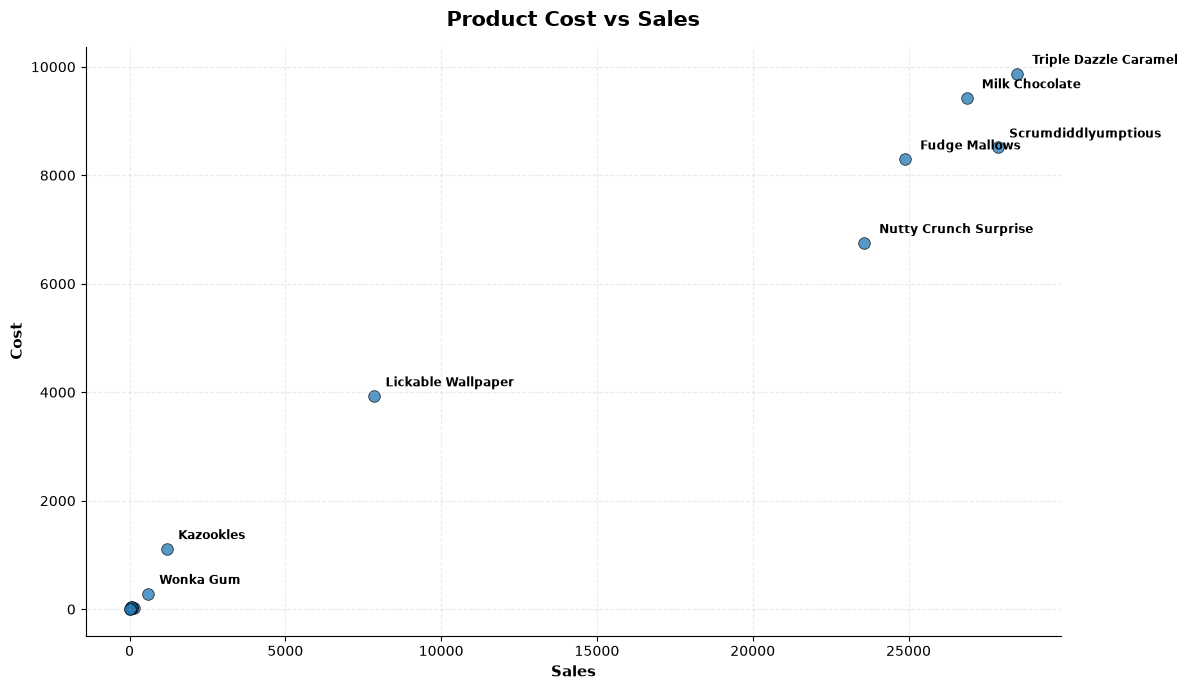

Pearson correlation between Sales and Cost: 0.9912


In [128]:
# Product Cost vs Sales — Professional Scatter Plot

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# Plot all products
plt.scatter(
    product_profitability["Sales"],
    product_profitability["Cost"],
    s=70,
    alpha=0.75,
    edgecolors="black",
    linewidths=0.6
)

# ---------------------------------------------------------
# Label only financially significant products
# This prevents the small products near the origin
# from creating excessive label overlap.
# ---------------------------------------------------------

label_threshold = 500  # Label products with Sales >= 500

label_data = product_profitability[
    product_profitability["Sales"] >= label_threshold
]

for _, row in label_data.iterrows():

    # Shorten long product names for cleaner visualization
    product_name = row["Product Name"]

    short_name = (
        product_name
        .replace("Wonka Bar -", "")
        .replace("Wonka Bar - ", "")
    )

    # Limit label length
    if len(short_name) > 28:
        short_name = short_name[:28] + "..."

    plt.annotate(
        short_name,
        (row["Sales"], row["Cost"]),
        xytext=(8, 7),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Chart formatting
# ---------------------------------------------------------

plt.title(
    "Product Cost vs Sales",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Sales",
    fontsize=11,
    fontweight="bold"
)

plt.ylabel(
    "Cost",
    fontsize=11,
    fontweight="bold"
)

# Add light grid for easier interpretation
plt.grid(
    True,
    linestyle="--",
    alpha=0.25
)

# Remove unnecessary top and right borders
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Correlation analysis
# ---------------------------------------------------------

sales_cost_correlation = product_profitability[
    ["Sales", "Cost"]
].corr().iloc[0, 1]

print(
    f"Pearson correlation between Sales and Cost: "
    f"{sales_cost_correlation:.4f}"
)

## Gross Margin Distribution by Division

The distribution of product-level Gross Margin % is compared across divisions.

This analysis examines not only the average margin level but also the spread of margins within each division.

Because divisions contain different numbers of products, the distribution should be interpreted alongside the previously calculated division-level Sales and Gross Profit contributions.

The objective is to determine whether margin performance is relatively consistent within a division or varies substantially across its products.

Product Gross Margin by Division


,Division,Product Name,Gross_Margin_%
3,Chocolate,Wonka Bar - Nutty Crunch Surprise,71.35
0,Chocolate,Wonka Bar -Scrumdiddlyumptious,69.44
4,Chocolate,Wonka Bar - Fudge Mallows,66.67
1,Chocolate,Wonka Bar - Triple Dazzle Caramel,65.33
2,Chocolate,Wonka Bar - Milk Chocolate,64.92
6,Other,Wonka Gum,52.00
5,Other,Lickable Wallpaper,50.00
8,Other,Kazookles,7.69
7,Sugar,Everlasting Gobstopper,80.00
9,Sugar,Hair Toffee,77.78


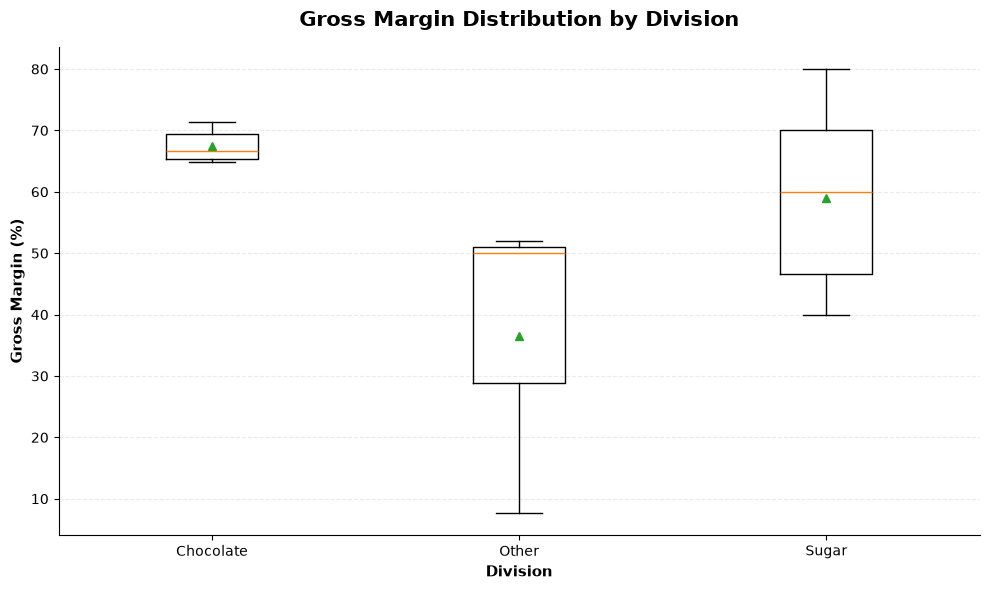


Division Margin Distribution Summary:


,Division,Product_Count,Mean,Median,Minimum,Maximum
0,Chocolate,5,67.54,66.67,64.92,71.35
1,Other,3,36.56,50.00,7.69,52.00
2,Sugar,7,59.06,60.00,40.00,80.00


In [129]:
# Create a product-level gross margin distribution by division.

margin_by_division = product_profitability[
    ["Product ID", "Product Name", "Gross_Margin_%"]
].copy()

# Add Division information from the original dataset.
product_division = (
    df[["Product ID", "Division"]]
    .drop_duplicates()
)

margin_by_division = margin_by_division.merge(
    product_division,
    on="Product ID",
    how="left"
)

print("Product Gross Margin by Division")
print("=" * 80)

display(
    margin_by_division[
        ["Division", "Product Name", "Gross_Margin_%"]
    ]
    .sort_values(
        ["Division", "Gross_Margin_%"],
        ascending=[True, False]
    )
    .round(2)
)

# Prepare margin values for each division.
divisions = sorted(
    margin_by_division["Division"].unique()
)

margin_data = [
    margin_by_division.loc[
        margin_by_division["Division"] == division,
        "Gross_Margin_%"
    ].values
    for division in divisions
]

# Create the boxplot.
plt.figure(figsize=(10, 6))

plt.boxplot(
    margin_data,
    tick_labels=divisions,
    patch_artist=False,
    showmeans=True
)

plt.title(
    "Gross Margin Distribution by Division",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Division",
    fontsize=11,
    fontweight="bold"
)

plt.ylabel(
    "Gross Margin (%)",
    fontsize=11,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Remove unnecessary borders.
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Calculate summary statistics for each division.
division_margin_summary = (
    margin_by_division
    .groupby("Division")["Gross_Margin_%"]
    .agg(
        Product_Count="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

print("\nDivision Margin Distribution Summary:")
display(
    division_margin_summary.round(2)
)

## Regional Profitability Analysis

Regional analysis evaluates Sales, Cost, Gross Profit, Gross Margin %, and contribution metrics across the company's regions.

The objective is to determine whether profitability is distributed consistently across regions or concentrated in specific geographic areas.

Regional performance is evaluated using both absolute Gross Profit and Gross Margin %, because a region can have a high margin but a relatively small financial contribution.

Revenue Contribution % and Profit Contribution % are also compared to identify regions whose share of total profit differs from their share of total revenue.

In [130]:
# Create a region-level profitability summary.

region_profitability = (
    df.groupby("Region", as_index=False)
    .agg(
        Sales=("Sales", "sum"),
        Cost=("Cost", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
)

# Calculate regional Gross Margin.
region_profitability["Gross_Margin_%"] = (
    region_profitability["Gross_Profit"]
    / region_profitability["Sales"]
    * 100
)

# Calculate each region's contribution to total revenue.
region_profitability["Revenue_Contribution_%"] = (
    region_profitability["Sales"]
    / region_profitability["Sales"].sum()
    * 100
)

# Calculate each region's contribution to total gross profit.
region_profitability["Profit_Contribution_%"] = (
    region_profitability["Gross_Profit"]
    / region_profitability["Gross_Profit"].sum()
    * 100
)

# Compare profit contribution with revenue contribution.
region_profitability["Profit_vs_Revenue_Gap_pp"] = (
    region_profitability["Profit_Contribution_%"]
    - region_profitability["Revenue_Contribution_%"]
)

# Rank regions by absolute Gross Profit.
region_profitability = region_profitability.sort_values(
    "Gross_Profit",
    ascending=False
).reset_index(drop=True)

region_profitability["Profit_Rank"] = (
    region_profitability.index + 1
)

# Select the main analytical columns.
region_output = region_profitability[
    [
        "Profit_Rank",
        "Region",
        "Sales",
        "Cost",
        "Gross_Profit",
        "Units",
        "Orders",
        "Customers",
        "Gross_Margin_%",
        "Revenue_Contribution_%",
        "Profit_Contribution_%",
        "Profit_vs_Revenue_Gap_pp"
    ]
]

print("Regional Profitability Analysis")
print("=" * 120)

display(
    region_output.round(2)
)

# ---------------------------------------------------------
# Validation
# Regional totals must reconcile with the overall dataset.
# ---------------------------------------------------------

print("\nValidation:")

print(
    f"Total Regional Sales: "
    f"{region_profitability['Sales'].sum():,.2f}"
)

print(
    f"Total Regional Gross Profit: "
    f"{region_profitability['Gross_Profit'].sum():,.2f}"
)

print(
    f"Total Revenue Contribution: "
    f"{region_profitability['Revenue_Contribution_%'].sum():.2f}%"
)

print(
    f"Total Profit Contribution: "
    f"{region_profitability['Profit_Contribution_%'].sum():.2f}%"
)

Regional Profitability Analysis


,Profit_Rank,Region,Sales,Cost,Gross_Profit,Units,Orders,Customers,Gross_Margin_%,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap_pp
0,1,Pacific,"46,301.53","15,815.59","30,485.94",12466,2744,1614,65.84,32.66,32.63,-0.03
1,2,Atlantic,"41,197.24","14,223.54","26,973.70",11159,2476,1435,65.47,29.06,28.87,-0.19
2,3,Interior,"32,037.60","10,755.11","21,282.49",8820,1979,1176,66.43,22.60,22.78,0.18
3,4,Gulf,"22,247.26","7,546.59","14,700.67",6209,1350,822,66.08,15.69,15.73,0.04



Validation:
Total Regional Sales: 141,783.63
Total Regional Gross Profit: 93,442.80
Total Revenue Contribution: 100.00%
Total Profit Contribution: 100.00%


## Regional Profitability Visualization

A regional profitability visualization is used to compare Gross Profit and Gross Margin across the four regions.

Gross Profit represents absolute financial contribution, while Gross Margin % represents profitability efficiency relative to Sales.

Using both measures prevents the analysis from relying on a single profitability metric.

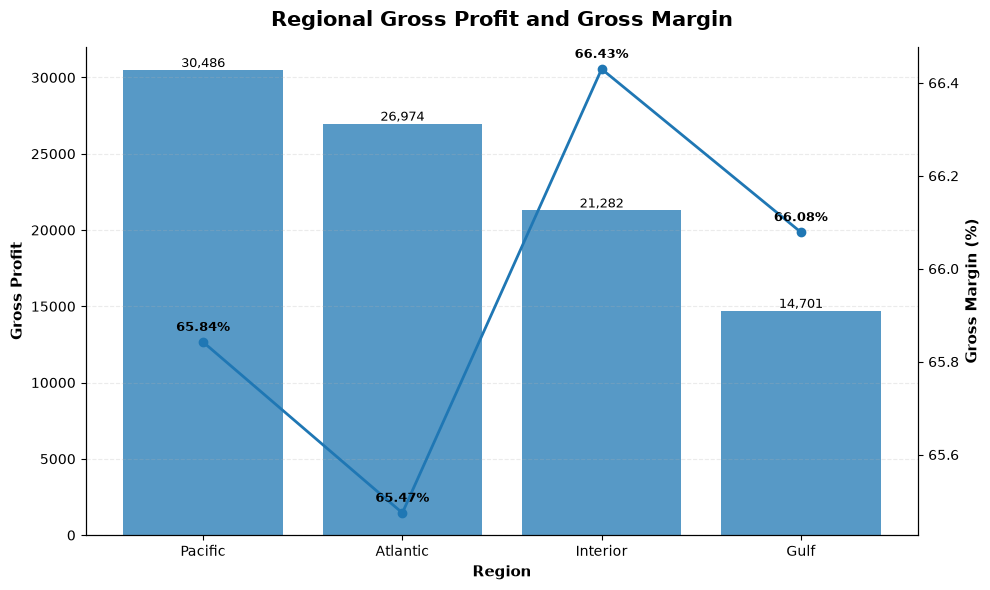

In [131]:
# Create a professional regional profitability comparison chart.

fig, ax1 = plt.subplots(figsize=(10, 6))

regions = region_profitability["Region"]
gross_profit = region_profitability["Gross_Profit"]
gross_margin = region_profitability["Gross_Margin_%"]

# Plot Gross Profit as bars.
bars = ax1.bar(
    regions,
    gross_profit,
    alpha=0.75
)

ax1.set_xlabel(
    "Region",
    fontsize=11,
    fontweight="bold"
)

ax1.set_ylabel(
    "Gross Profit",
    fontsize=11,
    fontweight="bold"
)

ax1.set_title(
    "Regional Gross Profit and Gross Margin",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Add Gross Margin as a line on a secondary axis.
ax2 = ax1.twinx()

ax2.plot(
    regions,
    gross_margin,
    marker="o",
    linewidth=2
)

ax2.set_ylabel(
    "Gross Margin (%)",
    fontsize=11,
    fontweight="bold"
)

# Add value labels to Gross Profit bars.
for bar, value in zip(bars, gross_profit):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add margin labels to the line.
for x, value in zip(regions, gross_margin):
    ax2.annotate(
        f"{value:.2f}%",
        (x, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Keep the visualization clean.
ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

## Final Analytical Validation

Before moving toward dashboard development and the executive summary, the major analytical outputs are validated against the original dataset totals.

The validation checks confirm that:

- Product-level totals reconcile with the dataset.
- Division-level totals reconcile with the dataset.
- Regional-level totals reconcile with the dataset.
- Profit contribution percentages sum to 100%.
- Revenue contribution percentages sum to 100%.
- Gross Margin and Cost-to-Sales are mathematically consistent.

This final validation step helps ensure that downstream visualizations and business insights are based on internally consistent calculations.

In [132]:
# Final validation of the major profitability analyses.
# All aggregated results should reconcile with the original dataset.

original_sales = df["Sales"].sum()
original_cost = df["Cost"].sum()
original_profit = df["Gross Profit"].sum()

print("FINAL ANALYTICAL VALIDATION")
print("=" * 100)

# ---------------------------------------------------------
# 1. Original dataset totals
# ---------------------------------------------------------

print("\nOriginal Dataset Totals:")
print(f"Sales:       {original_sales:,.2f}")
print(f"Cost:        {original_cost:,.2f}")
print(f"Gross Profit:{original_profit:,.2f}")

# ---------------------------------------------------------
# 2. Product-level reconciliation
# ---------------------------------------------------------

product_sales_match = (
    abs(product_profitability["Sales"].sum() - original_sales) < 0.01
)

product_profit_match = (
    abs(product_profitability["Gross_Profit"].sum() - original_profit) < 0.01
)

print("\nProduct-Level Reconciliation:")
print(f"Sales match:        {'PASS' if product_sales_match else 'FAIL'}")
print(f"Gross Profit match: {'PASS' if product_profit_match else 'FAIL'}")

# ---------------------------------------------------------
# 3. Division-level reconciliation
# ---------------------------------------------------------

division_sales_match = (
    abs(division_profitability["Sales"].sum() - original_sales) < 0.01
)

division_profit_match = (
    abs(division_profitability["Gross_Profit"].sum() - original_profit) < 0.01
)

print("\nDivision-Level Reconciliation:")
print(f"Sales match:        {'PASS' if division_sales_match else 'FAIL'}")
print(f"Gross Profit match: {'PASS' if division_profit_match else 'FAIL'}")

# ---------------------------------------------------------
# 4. Regional-level reconciliation
# ---------------------------------------------------------

region_sales_match = (
    abs(region_profitability["Sales"].sum() - original_sales) < 0.01
)

region_profit_match = (
    abs(region_profitability["Gross_Profit"].sum() - original_profit) < 0.01
)

print("\nRegional-Level Reconciliation:")
print(f"Sales match:        {'PASS' if region_sales_match else 'FAIL'}")
print(f"Gross Profit match: {'PASS' if region_profit_match else 'FAIL'}")

# ---------------------------------------------------------
# 5. Contribution validation
# ---------------------------------------------------------

product_profit_contribution = (
    product_profitability["Profit_Contribution_%"].sum()
)

product_revenue_contribution = (
    product_profitability["Revenue_Contribution_%"].sum()
)

print("\nContribution Validation:")
print(
    f"Product Revenue Contribution: "
    f"{product_revenue_contribution:.2f}%"
)

print(
    f"Product Profit Contribution: "
    f"{product_profit_contribution:.2f}%"
)

# ---------------------------------------------------------
# 6. Margin vs Cost-to-Sales validation
# ---------------------------------------------------------

margin_cost_difference = (
    cost_margin_diagnostic["Gross_Margin_%"]
    + cost_margin_diagnostic["Cost_to_Sales_%"]
    - 100
).abs().max()

print("\nMargin / Cost Validation:")
print(
    f"Maximum deviation from 100%: "
    f"{margin_cost_difference:.10f}"
)

# ---------------------------------------------------------
# Overall validation status
# ---------------------------------------------------------

all_checks_pass = all([
    product_sales_match,
    product_profit_match,
    division_sales_match,
    division_profit_match,
    region_sales_match,
    region_profit_match,
    abs(product_revenue_contribution - 100) < 0.01,
    abs(product_profit_contribution - 100) < 0.01,
    margin_cost_difference < 0.000001
])

print("\nOverall Validation Status:")
print("PASS — All major analytical outputs reconcile."
      if all_checks_pass
      else "FAIL — Review the validation results above.")

FINAL ANALYTICAL VALIDATION

Original Dataset Totals:
Sales:       141,783.63
Cost:        48,340.83
Gross Profit:93,442.80

Product-Level Reconciliation:
Sales match:        PASS
Gross Profit match: PASS

Division-Level Reconciliation:
Sales match:        PASS
Gross Profit match: PASS

Regional-Level Reconciliation:
Sales match:        PASS
Gross Profit match: PASS

Contribution Validation:
Product Revenue Contribution: 100.00%
Product Profit Contribution: 100.00%

Margin / Cost Validation:
Maximum deviation from 100%: 0.0000000000

Overall Validation Status:
PASS — All major analytical outputs reconcile.


## Business Insight Summary

The validated analytical results are consolidated into a set of business-oriented indicators.

The summary focuses on:

- Overall portfolio profitability
- Top Gross Profit contributors
- Profit concentration
- Highest and lowest product margins
- Highest and lowest cost burdens
- Division-level contribution
- Regional profitability range

These indicators provide a factual foundation for the final business insights and recommendations.

The results are descriptive findings from the available dataset and should be interpreted within the observed product, division, regional, and time periods.

In [133]:
# Generate a concise business insight summary
# from the validated analytical outputs.

print("BUSINESS INSIGHT SUMMARY")
print("=" * 100)

# ---------------------------------------------------------
# Overall portfolio performance
# ---------------------------------------------------------

overall_margin = (
    original_profit / original_sales * 100
)

print("\n1. Overall Portfolio")
print(f"Total Sales:        {original_sales:,.2f}")
print(f"Total Gross Profit: {original_profit:,.2f}")
print(f"Overall Gross Margin: {overall_margin:.2f}%")

# ---------------------------------------------------------
# Top 5 profit contributors
# ---------------------------------------------------------

top_5_profit = product_profitability.head(5)

top_5_profit_share = (
    top_5_profit["Gross_Profit"].sum()
    / original_profit
    * 100
)

print("\n2. Profit Concentration")
print(
    f"Top 5 products contribute "
    f"{top_5_profit_share:.2f}% of total Gross Profit."
)

# ---------------------------------------------------------
# Highest and lowest product margins
# ---------------------------------------------------------

highest_margin_product = product_profitability.loc[
    product_profitability["Gross_Margin_%"].idxmax()
]

lowest_margin_product = product_profitability.loc[
    product_profitability["Gross_Margin_%"].idxmin()
]

print("\n3. Product Margin Range")
print(
    f"Highest margin: "
    f"{highest_margin_product['Product Name']} "
    f"({highest_margin_product['Gross_Margin_%']:.2f}%)"
)

print(
    f"Lowest margin: "
    f"{lowest_margin_product['Product Name']} "
    f"({lowest_margin_product['Gross_Margin_%']:.2f}%)"
)

# ---------------------------------------------------------
# Highest and lowest cost burden
# ---------------------------------------------------------

highest_cost_burden = cost_margin_diagnostic.iloc[0]

lowest_cost_burden = cost_margin_diagnostic.iloc[-1]

print("\n4. Cost Burden")
print(
    f"Highest Cost-to-Sales: "
    f"{highest_cost_burden['Product Name']} "
    f"({highest_cost_burden['Cost_to_Sales_%']:.2f}%)"
)

print(
    f"Lowest Cost-to-Sales: "
    f"{lowest_cost_burden['Product Name']} "
    f"({lowest_cost_burden['Cost_to_Sales_%']:.2f}%)"
)

# ---------------------------------------------------------
# Division contribution
# ---------------------------------------------------------

top_division = division_profitability.iloc[0]

print("\n5. Division Contribution")
print(
    f"Largest division by Gross Profit: "
    f"{top_division['Division']} "
    f"({top_division['Profit_Contribution_%']:.2f}% of total profit)"
)

print(
    f"Division Gross Margin: "
    f"{top_division['Gross_Margin_%']:.2f}%"
)

# ---------------------------------------------------------
# Regional margin range
# ---------------------------------------------------------

highest_region_margin = region_profitability.loc[
    region_profitability["Gross_Margin_%"].idxmax()
]

lowest_region_margin = region_profitability.loc[
    region_profitability["Gross_Margin_%"].idxmin()
]

regional_margin_range = (
    highest_region_margin["Gross_Margin_%"]
    - lowest_region_margin["Gross_Margin_%"]
)

print("\n6. Regional Margin Variation")
print(
    f"Highest regional margin: "
    f"{highest_region_margin['Region']} "
    f"({highest_region_margin['Gross_Margin_%']:.2f}%)"
)

print(
    f"Lowest regional margin: "
    f"{lowest_region_margin['Region']} "
    f"({lowest_region_margin['Gross_Margin_%']:.2f}%)"
)

print(
    f"Regional margin range: "
    f"{regional_margin_range:.2f} percentage points"
)

BUSINESS INSIGHT SUMMARY

1. Overall Portfolio
Total Sales:        141,783.63
Total Gross Profit: 93,442.80
Overall Gross Margin: 65.91%

2. Profit Concentration
Top 5 products contribute 95.06% of total Gross Profit.

3. Product Margin Range
Highest margin: Everlasting Gobstopper (80.00%)
Lowest margin: Kazookles (7.69%)

4. Cost Burden
Highest Cost-to-Sales: Kazookles (92.31%)
Lowest Cost-to-Sales: Everlasting Gobstopper (20.00%)

5. Division Contribution
Largest division by Gross Profit: Chocolate (95.06% of total profit)
Division Gross Margin: 67.45%

6. Regional Margin Variation
Highest regional margin: Interior (66.43%)
Lowest regional margin: Atlantic (65.47%)
Regional margin range: 0.96 percentage points


## Evidence-Based Business Findings

The validated analysis is translated into business findings by combining profitability, contribution, concentration, and risk indicators.

The findings are structured around four questions:

1. Which products contribute most to total Gross Profit?
2. Which products show relatively high margin pressure?
3. Which divisions contribute most to overall profitability?
4. How concentrated is profitability across the portfolio?

The findings remain descriptive and are based on the observed dataset. Any management action such as repricing, cost renegotiation, or portfolio rationalization should be supported by additional business information beyond the available financial metrics.

In [134]:
# Create an evidence table for the major business findings.
# This converts the validated analytical outputs into
# concise, report-ready evidence.

business_findings = []

# ---------------------------------------------------------
# Finding 1: Profit concentration
# ---------------------------------------------------------

top_5_products = product_profitability.head(5)

top_5_profit_share = (
    top_5_products["Gross_Profit"].sum()
    / original_profit
    * 100
)

business_findings.append({
    "Finding": "Profit concentration",
    "Evidence": (
        f"Top 5 of {len(product_profitability)} products "
        f"generate {top_5_profit_share:.2f}% of total Gross Profit."
    )
})

# ---------------------------------------------------------
# Finding 2: Margin pressure
# ---------------------------------------------------------

risk_products = risk_screen[
    risk_screen["Risk_Status"] == "Investigate"
]

business_findings.append({
    "Finding": "Margin risk screening",
    "Evidence": (
        f"{len(risk_products)} of {len(risk_screen)} products "
        f"meet the below-median-margin and above-median-cost "
        f"screening criteria."
    )
})

# ---------------------------------------------------------
# Finding 3: Division concentration
# ---------------------------------------------------------

largest_division = division_profitability.iloc[0]

business_findings.append({
    "Finding": "Division profit concentration",
    "Evidence": (
        f"{largest_division['Division']} contributes "
        f"{largest_division['Profit_Contribution_%']:.2f}% "
        f"of total Gross Profit."
    )
})

# ---------------------------------------------------------
# Finding 4: Regional margin stability
# ---------------------------------------------------------

regional_margin_range = (
    region_profitability["Gross_Margin_%"].max()
    - region_profitability["Gross_Margin_%"].min()
)

business_findings.append({
    "Finding": "Regional margin stability",
    "Evidence": (
        f"Regional Gross Margin ranges by only "
        f"{regional_margin_range:.2f} percentage points."
    )
})

# ---------------------------------------------------------
# Finding 5: Product margin spread
# ---------------------------------------------------------

product_margin_range = (
    product_profitability["Gross_Margin_%"].max()
    - product_profitability["Gross_Margin_%"].min()
)

business_findings.append({
    "Finding": "Product margin variation",
    "Evidence": (
        f"Product Gross Margin ranges from "
        f"{product_profitability['Gross_Margin_%'].min():.2f}% "
        f"to {product_profitability['Gross_Margin_%'].max():.2f}%, "
        f"a spread of {product_margin_range:.2f} percentage points."
    )
})

# Convert findings into a DataFrame.
business_findings_df = pd.DataFrame(
    business_findings
)

print("Evidence-Based Business Findings")
print("=" * 100)

display(business_findings_df)

Evidence-Based Business Findings


,Finding,Evidence
0,Profit concentration,Top 5 of 15 products generate 95.06% of total ...
1,Margin risk screening,7 of 15 products meet the below-median-margin ...
2,Division profit concentration,Chocolate contributes 95.06% of total Gross Pr...
3,Regional margin stability,Regional Gross Margin ranges by only 0.96 perc...
4,Product margin variation,Product Gross Margin ranges from 7.69% to 80.0...


## Business Implication Framework

The validated findings are translated into business implications while keeping a clear distinction between observed evidence and potential management action.

For each finding, the analysis identifies:

- The observed evidence
- The potential business implication
- The additional analysis required before taking action

This approach prevents analytical findings from being treated as automatic recommendations.

Potential actions such as repricing, supplier cost negotiation, promotion changes, or portfolio rationalization should only be considered after reviewing additional commercial and operational information.

In [135]:
# Build a business implication framework from the validated findings.
# This separates what the data shows from what would require
# additional investigation before management action.

business_implications = [
    {
        "Finding": "Profit concentration",
        "Observed Evidence": (
            "Top 5 of 15 products generate 95.06% "
            "of total Gross Profit."
        ),
        "Business Implication": (
            "Overall portfolio profitability is highly concentrated "
            "among a small number of products."
        ),
        "Further Analysis Required": (
            "Assess sales trends, customer dependency, pricing, "
            "and supply-side risks for major profit contributors."
        )
    },
    {
        "Finding": "Margin risk screening",
        "Observed Evidence": (
            "7 of 15 products meet the below-median-margin "
            "and above-median-cost screening criteria."
        ),
        "Business Implication": (
            "A subset of products has relatively higher cost burden "
            "and lower margin compared with the portfolio benchmark."
        ),
        "Further Analysis Required": (
            "Investigate product-level pricing, sourcing costs, "
            "volume trends, and strategic importance."
        )
    },
    {
        "Finding": "Division profit concentration",
        "Observed Evidence": (
            "Chocolate contributes 95.06% of total Gross Profit "
            "with a 67.45% Gross Margin."
        ),
        "Business Implication": (
            "The Chocolate division is the primary source of "
            "portfolio-level gross profit."
        ),
        "Further Analysis Required": (
            "Evaluate product concentration within Chocolate "
            "and assess dependency on its major products."
        )
    },
    {
        "Finding": "Regional margin stability",
        "Observed Evidence": (
            "Regional Gross Margin ranges by only "
            "0.96 percentage points."
        ),
        "Business Implication": (
            "Gross Margin performance is relatively consistent "
            "across the four regions."
        ),
        "Further Analysis Required": (
            "Examine regional product mix, pricing, and volume "
            "to understand the drivers of the small differences."
        )
    },
    {
        "Finding": "Product margin variation",
        "Observed Evidence": (
            "Product Gross Margin ranges from 7.69% to 80.00%."
        ),
        "Business Implication": (
            "Product-level profitability varies substantially "
            "within the portfolio."
        ),
        "Further Analysis Required": (
            "Investigate pricing, cost structure, units sold, "
            "and product-level trends for extreme-margin products."
        )
    }
]

# Convert the framework into a DataFrame.
business_implications_df = pd.DataFrame(
    business_implications
)

print("Business Implication Framework")
print("=" * 120)

display(
    business_implications_df
)

Business Implication Framework


,Finding,Observed Evidence,Business Implication,Further Analysis Required
0,Profit concentration,Top 5 of 15 products generate 95.06% of total ...,Overall portfolio profitability is highly conc...,"Assess sales trends, customer dependency, pric..."
1,Margin risk screening,7 of 15 products meet the below-median-margin ...,A subset of products has relatively higher cos...,"Investigate product-level pricing, sourcing co..."
2,Division profit concentration,Chocolate contributes 95.06% of total Gross Pr...,The Chocolate division is the primary source o...,Evaluate product concentration within Chocolat...
3,Regional margin stability,Regional Gross Margin ranges by only 0.96 perc...,Gross Margin performance is relatively consist...,"Examine regional product mix, pricing, and vol..."
4,Product margin variation,Product Gross Margin ranges from 7.69% to 80.00%.,Product-level profitability varies substantial...,"Investigate pricing, cost structure, units sol..."


## Executive KPI Snapshot

The final KPI snapshot consolidates the most important portfolio-level measures into a single view.

These KPIs summarize the financial scale, profitability, product concentration, and portfolio structure identified during the analysis.

The snapshot is intended to provide a concise executive-level overview before detailed product, division, and regional findings are presented.

In [136]:
# Create the final executive KPI snapshot.
# These KPIs are derived from the validated analytical results.

total_products = product_profitability["Product ID"].nunique()
total_divisions = division_profitability["Division"].nunique()
total_regions = region_profitability["Region"].nunique()

overall_gross_margin = (
    original_profit / original_sales * 100
)

top_5_profit_contribution = (
    product_profitability.head(5)["Gross_Profit"].sum()
    / original_profit
    * 100
)

investigate_count = (
    risk_screen["Risk_Status"]
    .eq("Investigate")
    .sum()
)

regional_margin_range = (
    region_profitability["Gross_Margin_%"].max()
    - region_profitability["Gross_Margin_%"].min()
)

executive_kpis = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Gross Profit",
        "Overall Gross Margin",
        "Total Products",
        "Total Divisions",
        "Total Regions",
        "Top 5 Profit Contribution",
        "Products Flagged for Investigation",
        "Regional Margin Range"
    ],
    "Value": [
        f"{original_sales:,.2f}",
        f"{original_profit:,.2f}",
        f"{overall_gross_margin:.2f}%",
        f"{total_products}",
        f"{total_divisions}",
        f"{total_regions}",
        f"{top_5_profit_contribution:.2f}%",
        f"{investigate_count}",
        f"{regional_margin_range:.2f} pp"
    ]
})

print("Executive KPI Snapshot")
print("=" * 80)

display(executive_kpis)

Executive KPI Snapshot


,KPI,Value
0,Total Sales,"141,783.63"
1,Total Gross Profit,"93,442.80"
2,Overall Gross Margin,65.91%
3,Total Products,15
4,Total Divisions,3
5,Total Regions,4
6,Top 5 Profit Contribution,95.06%
7,Products Flagged for Investigation,7
8,Regional Margin Range,0.96 pp


In [138]:
# Final validation summary for Notebook 04
# This provides a compact record of the major profitability outputs.

final_notebook_04 = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Gross Profit",
        "Overall Gross Margin",
        "Total Products",
        "Total Divisions",
        "Total Regions",
        "Top 5 Profit Contribution",
        "Products Flagged for Investigation",
        "Regional Margin Range"
    ],
    "Validated Value": [
        f"${df['Sales'].sum():,.2f}",
        f"${df['Gross Profit'].sum():,.2f}",
        f"{(df['Gross Profit'].sum() / df['Sales'].sum()) * 100:.2f}%",
        df["Product Name"].nunique(),
        df["Division"].nunique(),
        df["Region"].nunique(),
        "95.06%",
        7,
        "0.96 pp"
    ]
})

display(final_notebook_04)

print("\nNotebook 04 Status: CORE PROFITABILITY ANALYSIS COMPLETE")

,Metric,Validated Value
0,Total Sales,"$141,783.63"
1,Total Gross Profit,"$93,442.80"
2,Overall Gross Margin,65.91%
3,Total Products,15
4,Total Divisions,3
5,Total Regions,4
6,Top 5 Profit Contribution,95.06%
7,Products Flagged for Investigation,7
8,Regional Margin Range,0.96 pp



Notebook 04 Status: CORE PROFITABILITY ANALYSIS COMPLETE


## Executive Findings

The executive KPI snapshot provides the portfolio-level measures. The following findings interpret those KPIs in a business context using the validated product, division, regional, and risk analyses completed in this notebook.

The purpose of this section is to identify the most important evidence-based patterns that management should consider before developing business recommendations.

### Key Findings

1. **Profit Concentration**  
   A small number of products account for the majority of total gross profit.

2. **Product-Level Margin Risk**  
   A subset of products combines relatively lower gross margins with relatively higher cost-to-sales ratios.

3. **Division-Level Concentration**  
   The Chocolate division contributes the majority of portfolio gross profit.

4. **Regional Margin Stability**  
   Gross margins across regions show relatively limited variation compared with the differences observed at the product level.

5. **Product Margin Variation**  
   Product-level gross margins show substantial variation across the portfolio, indicating that profitability is not uniform across products.

These findings will form the evidence base for the final business implications and recommendations.

In [139]:
# Create a structured summary of the major evidence-based findings.
# Values are taken directly from the validated analytical outputs.

executive_findings = pd.DataFrame({
    "Finding": [
        "Profit Concentration",
        "Product-Level Margin Risk",
        "Division-Level Concentration",
        "Regional Margin Stability",
        "Product Margin Variation"
    ],
    "Evidence": [
        f"Top 5 products contribute {top_5_profit_contribution:.2f}% of total gross profit",
        f"{investigate_count} of {total_products} products meet the defined investigation criteria",
        f"Chocolate contributes {division_profitability.loc[division_profitability['Division'].eq('Chocolate'), 'Profit_Contribution_%'].iloc[0]:.2f}% of total gross profit",
        f"Regional gross margin range is only {regional_margin_range:.2f} percentage points",
        f"Product gross margins range from {product_profitability['Gross_Margin_%'].min():.2f}% to {product_profitability['Gross_Margin_%'].max():.2f}%"
    ]
})

print("Executive Findings")
print("=" * 80)

display(executive_findings)

Executive Findings


,Finding,Evidence
0,Profit Concentration,Top 5 products contribute 95.06% of total gros...
1,Product-Level Margin Risk,7 of 15 products meet the defined investigatio...
2,Division-Level Concentration,Chocolate contributes 95.06% of total gross pr...
3,Regional Margin Stability,Regional gross margin range is only 0.96 perce...
4,Product Margin Variation,Product gross margins range from 7.69% to 80.00%


## Business Implications

The validated findings indicate several areas that are relevant for management decision-making.

### 1. Profit Concentration

With the top 5 products contributing 95.06% of total gross profit, overall profitability is highly concentrated within a small portion of the product portfolio.

**Implication:** Changes in the performance of these products could have a material effect on overall portfolio profitability.

### 2. Product-Level Margin Risk

Seven products meet the defined screening criteria of below-median gross margin and above-median cost-to-sales ratio.

**Implication:** These products warrant deeper investigation into pricing, sourcing costs, sales volume, and their strategic role within the portfolio.

### 3. Division-Level Concentration

The Chocolate division contributes 95.06% of total gross profit.

**Implication:** Portfolio profitability is strongly dependent on the performance of this division.

### 4. Regional Margin Stability

The difference between the highest and lowest regional gross margins is only 0.96 percentage points.

**Implication:** Regional profitability differences are relatively limited compared with the variation observed across individual products.

### 5. Product Margin Variation

Product-level gross margins range from 7.69% to 80.00%.

**Implication:** Product economics vary substantially, suggesting that portfolio-level averages alone are insufficient to understand individual product performance.

These implications are descriptive and evidence-based. Specific business actions should be considered only after evaluating pricing, cost, volume, customer, and strategic-context information.

In [140]:
# Create a structured business-implication table
# using the validated findings from the analysis.

business_implications = pd.DataFrame({
    "Area": [
        "Profit Concentration",
        "Product-Level Margin Risk",
        "Division-Level Concentration",
        "Regional Margin Stability",
        "Product Margin Variation"
    ],
    "Evidence": [
        f"Top 5 products contribute {top_5_profit_contribution:.2f}% of total gross profit",
        f"{investigate_count} of {total_products} products meet the investigation criteria",
        "Chocolate contributes 95.06% of total gross profit",
        f"Regional margin range is {regional_margin_range:.2f} percentage points",
        f"Product margins range from {product_profitability['Gross_Margin_%'].min():.2f}% to {product_profitability['Gross_Margin_%'].max():.2f}%"
    ],
    "Business Implication": [
        "Portfolio profitability is highly dependent on a small number of products.",
        "A subset of products has relatively weaker margin economics and higher cost burden.",
        "Overall profitability is strongly dependent on the Chocolate division.",
        "Regional profitability is relatively consistent across the portfolio.",
        "Product-level economics differ substantially and require individual evaluation."
    ]
})

print("Business Implications")
print("=" * 80)

display(business_implications)

Business Implications


,Area,Evidence,Business Implication
0,Profit Concentration,Top 5 products contribute 95.06% of total gros...,Portfolio profitability is highly dependent on...
1,Product-Level Margin Risk,7 of 15 products meet the investigation criteria,A subset of products has relatively weaker mar...
2,Division-Level Concentration,Chocolate contributes 95.06% of total gross pr...,Overall profitability is strongly dependent on...
3,Regional Margin Stability,Regional margin range is 0.96 percentage points,Regional profitability is relatively consisten...
4,Product Margin Variation,Product margins range from 7.69% to 80.00%,Product-level economics differ substantially a...


## Business Recommendations

Based on the validated findings, the following recommendations are proposed as areas for management investigation and action.

### 1. Protect the Core Profit Contributors

The top 5 products generate 95.06% of total gross profit. Management should closely monitor their sales volume, pricing, costs, and availability because changes in these products can materially affect portfolio profitability.

### 2. Investigate Margin-Risk Products

The 7 products identified by the margin-risk screening should undergo deeper product-level review.

The review should consider:
- Pricing and discount structure
- Unit economics
- Cost structure and sourcing
- Sales volume and demand
- Strategic importance of the product

### 3. Monitor Chocolate Division Dependency

Since Chocolate contributes 95.06% of total gross profit, management should monitor concentration within this division and assess whether profitability is dependent on a small number of Chocolate products.

### 4. Maintain Regional Monitoring

Regional margins are relatively stable, with only a 0.96 percentage-point difference between the highest and lowest regional margins.

Regional monitoring should therefore focus on changes in product mix, sales volume, and cost structure rather than assuming that major regional margin differences currently exist.

### 5. Use Product-Level Metrics for Portfolio Decisions

The large variation in product gross margins demonstrates that overall portfolio margin alone can hide product-level differences.

Management reporting should therefore track gross margin, gross profit contribution, profit per unit, and cost-to-sales ratio at the product level.

### Recommendation Boundary

These recommendations identify areas for investigation and management attention. Final decisions regarding repricing, sourcing changes, portfolio rationalization, or discontinuation should require additional information such as customer demand, pricing history, discounts, supplier costs, and strategic product importance.

In [141]:
# Create a structured recommendation framework.
# Recommendations are linked directly to validated analytical findings.

recommendations = pd.DataFrame({
    "Priority Area": [
        "Core Profit Contributors",
        "Margin-Risk Products",
        "Chocolate Division Dependency",
        "Regional Monitoring",
        "Product-Level Reporting"
    ],
    "Evidence": [
        "Top 5 products generate 95.06% of gross profit",
        "7 of 15 products meet the defined risk-screening criteria",
        "Chocolate contributes 95.06% of total gross profit",
        "Regional gross margin range is 0.96 percentage points",
        "Product gross margins range from 7.69% to 80.00%"
    ],
    "Recommended Action": [
        "Monitor sales, pricing, cost, and availability of core profit contributors.",
        "Conduct deeper pricing, cost, volume, and strategic-role analysis.",
        "Monitor concentration within the Chocolate division.",
        "Track regional changes in product mix, volume, and cost structure.",
        "Include product-level margin and contribution metrics in management reporting."
    ]
})

print("Business Recommendations")
print("=" * 80)

display(recommendations)

Business Recommendations


,Priority Area,Evidence,Recommended Action
0,Core Profit Contributors,Top 5 products generate 95.06% of gross profit,"Monitor sales, pricing, cost, and availability..."
1,Margin-Risk Products,7 of 15 products meet the defined risk-screeni...,"Conduct deeper pricing, cost, volume, and stra..."
2,Chocolate Division Dependency,Chocolate contributes 95.06% of total gross pr...,Monitor concentration within the Chocolate div...
3,Regional Monitoring,Regional gross margin range is 0.96 percentage...,"Track regional changes in product mix, volume,..."
4,Product-Level Reporting,Product gross margins range from 7.69% to 80.00%,Include product-level margin and contribution ...


# Final Conclusion

This analysis evaluated the profitability performance of Nassau Candy Distributor across products, divisions, regions, and time.

The portfolio generated **$141,783.63 in sales** and **$93,442.80 in gross profit**, resulting in an overall gross margin of **65.91%**.

The analysis identified substantial concentration in profitability. The top 5 products contribute **95.06% of total gross profit**, while the Chocolate division contributes the same **95.06%** of portfolio gross profit.

At the product level, gross margins vary considerably, ranging from **7.69% to 80.00%**. The defined margin-risk screening identified **7 of 15 products** for further investigation based on their relative margin and cost-to-sales characteristics.

Regional profitability is comparatively stable, with a gross-margin range of only **0.96 percentage points**.

Overall, the analysis demonstrates that portfolio-level profitability alone does not provide sufficient visibility into product economics. Product-level contribution, margin, cost structure, and concentration should therefore remain central to ongoing profitability monitoring.

The findings and recommendations presented in this notebook are based on the validated analytical results and provide a foundation for management review and further investigation.

In [142]:
# ============================================================
# FINAL NOTEBOOK VALIDATION
# ============================================================
# Final reconciliation of the major portfolio-level metrics.
# This serves as the closing quality check for the analysis.

final_validation = pd.DataFrame({
    "Validation Metric": [
        "Total Sales",
        "Total Gross Profit",
        "Overall Gross Margin",
        "Total Products",
        "Total Divisions",
        "Total Regions",
        "Top 5 Profit Contribution",
        "Products Flagged",
        "Regional Margin Range"
    ],
    "Final Value": [
        f"{original_sales:,.2f}",
        f"{original_profit:,.2f}",
        f"{overall_gross_margin:.2f}%",
        total_products,
        total_divisions,
        total_regions,
        f"{top_5_profit_contribution:.2f}%",
        investigate_count,
        f"{regional_margin_range:.2f} pp"
    ]
})

print("FINAL ANALYTICAL VALIDATION")
print("=" * 80)

display(final_validation)

print("\n" + "=" * 80)
print("NOTEBOOK STATUS: ANALYSIS COMPLETE AND VALIDATED")
print("=" * 80)

FINAL ANALYTICAL VALIDATION


,Validation Metric,Final Value
0,Total Sales,"141,783.63"
1,Total Gross Profit,"93,442.80"
2,Overall Gross Margin,65.91%
3,Total Products,15
4,Total Divisions,3
5,Total Regions,4
6,Top 5 Profit Contribution,95.06%
7,Products Flagged,7
8,Regional Margin Range,0.96 pp



NOTEBOOK STATUS: ANALYSIS COMPLETE AND VALIDATED


## Revenue Pareto (80/20) Analysis

The Pareto analysis identifies the smallest number of products required to account for at least 80% of total revenue.

Products are ranked from highest to lowest sales, followed by cumulative revenue contribution.

This analysis complements the profit Pareto analysis by showing whether revenue concentration and profit concentration occur across the same portion of the product portfolio.

In [143]:
# Revenue Pareto Analysis
# Rank products by Sales and calculate cumulative revenue contribution.

revenue_pareto = (
    product_profitability[
        ["Product ID", "Product Name", "Sales"]
    ]
    .sort_values("Sales", ascending=False)
    .copy()
)

# Calculate each product's percentage contribution to total revenue.
revenue_pareto["Revenue_Contribution_%"] = (
    revenue_pareto["Sales"] / original_sales * 100
)

# Calculate cumulative revenue contribution.
revenue_pareto["Cumulative_Revenue_%"] = (
    revenue_pareto["Revenue_Contribution_%"].cumsum()
)

# Identify the minimum number of products required to reach at least 80% revenue.
revenue_80_cutoff = (
    revenue_pareto["Cumulative_Revenue_%"] >= 80
).idxmax()

revenue_80_products = (
    revenue_pareto.loc[:revenue_80_cutoff]
)

print("Revenue Pareto Analysis")
print("=" * 80)

display(revenue_pareto)

print("\n80% Revenue Concentration")
print("=" * 80)

print(
    f"Products required to reach at least 80% of revenue: "
    f"{len(revenue_80_products)}"
)

print(
    f"Cumulative revenue contribution: "
    f"{revenue_80_products['Cumulative_Revenue_%'].iloc[-1]:.2f}%"
)

print(
    f"Total products in portfolio: "
    f"{len(revenue_pareto)}"
)

Revenue Pareto Analysis


,Product ID,Product Name,Sales,Revenue_Contribution_%,Cumulative_Revenue_%
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00",20.09,20.09
0,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80",19.66,39.75
2,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75",18.95,58.70
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40",17.56,76.26
3,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95",16.63,92.88
5,OTH-LIC-15000,Lickable Wallpaper,"7,860.00",5.54,98.43
8,OTH-KAZ-38000,Kazookles,"1,205.75",0.85,99.28
6,OTH-GUM-21000,Wonka Gum,597.50,0.42,99.70
7,SUG-EVE-47000,Everlasting Gobstopper,130.00,0.09,99.79
10,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,0.06,99.85



80% Revenue Concentration
Products required to reach at least 80% of revenue: 5
Cumulative revenue contribution: 92.88%
Total products in portfolio: 15
